# ¿Cómo votará cada diputado? Predicción de votaciones de la Cámara con GNN

Proyecto final IIC3641 GML, 2026-2.

Este notebook genera todos los resultados de las presentaciones. Se puede correr de punta a punta:
si no encuentra los datos en `../datos/`, los baja de la API de datos abiertos de la Cámara (unos 20 minutos).

**Pregunta.** Los diputados votan casi siempre con su partido, así que "votar como la mayoría del partido" ya acierta
mucho. Pero eso solo sirve si se sabe cómo votó el partido. Dado un conteo parcial de una votación, ¿quién se va a
salir de la línea de su partido, y cómo votan los independientes, que no tienen línea que seguir?

**Dos escenarios.**

- **B. Votación en curso** (principal). Se ve una fracción de los votos (50% por defecto) y hay que completar el resto.
  El baseline es la mayoría visible del propio partido, que por construcción nunca predice una ruptura.
- **A. Antes de votar** (secundario). De la votación nueva solo se conoce el proyecto: texto, autores, comisión, si es
  mensaje del Ejecutivo, tipo de votación y trámite. No se ve ningún voto. Sirve para medir cuánto se sabe sin conteo.

Contenido:

1. Datos y limpieza
2. Análisis descriptivo
3. Partición temporal y features
4. Baselines sin GNN, incluido NOMINATE (pedido en el feedback de la propuesta)
5. Grafo heterogéneo y modelo R-GCN
6. Resultados (5 semillas): R-GCN, combinación R-GCN + NOMINATE, ablaciones y subgrupos
7. Votos fuera de línea: precisión, recall y AP (pedido en el feedback)
8. Predicción del resultado de la votación (escenario A)
9. Interpretación: embeddings de diputados

In [1]:
import json, os, subprocess, sys, time, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import HeteroConv, SAGEConv
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
RAIZ = Path("..").resolve()
DATOS, FIG, RES = RAIZ / "datos", RAIZ / "figuras", RAIZ / "resultados"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEMILLAS = [0, 1, 2, 3, 4]
CLASES = ["a favor", "en contra", "abstención"]

# Colores fijos para todas las figuras (los mismos de las presentaciones)
C_SI, C_NO, C_ABS = "#2E7D4F", "#C8102E", "#E0A100"
C_TINTA, C_GRIS, C_GNN = "#1B2A41", "#9AA3AE", "#C8102E"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.family": "DejaVu Sans", "axes.titleweight": "bold"})
print("torch", torch.__version__, "| dispositivo:", DEVICE)

torch 2.3.0+cu121 | dispositivo: cuda


## 1. Datos

Fuente: API de datos abiertos de la Cámara (`opendata.camara.cl`), servicios `WSLegislativo` y `WSDiputado`.
Son datos abiertos. Se usan todas las votaciones de sala del período legislativo 11-03-2022 a 10-03-2026.
El script `codigo/descarga_datos.py` guarda seis CSV:

| archivo | contenido |
|---|---|
| `votaciones.csv` | una fila por votación: fecha, totales, quórum, resultado, tipo, boletín, tipo de votación, trámite, artículo |
| `votos.csv` | una fila por voto individual: votación, diputado, opción |
| `proyectos.csv` | una fila por boletín: nombre, fecha de ingreso, mensaje o moción, cámara de origen |
| `autores.csv` | autores de cada moción |
| `diputados.csv`, `militancias.csv` | diputados y su partido con fechas |

In [2]:
if not (DATOS / "votaciones.csv").exists():
    subprocess.run([sys.executable, str(RAIZ / "codigo" / "descarga_datos.py")], check=True)

vot = pd.read_csv(DATOS / "votaciones.csv", parse_dates=["fecha"])
votos = pd.read_csv(DATOS / "votos.csv")
proy = pd.read_csv(DATOS / "proyectos.csv", parse_dates=["fecha_ingreso"])
autores = pd.read_csv(DATOS / "autores.csv")
dips = pd.read_csv(DATOS / "diputados.csv")
mil = pd.read_csv(DATOS / "militancias.csv", parse_dates=["inicio", "termino"])

print(f"votaciones del período: {len(vot):,}")
print(vot.tipo.value_counts().to_string())
print(f"\nvotos individuales: {len(votos):,}")
print(votos.opcion.value_counts().to_string())

votaciones del período: 6,480
tipo
Proyecto de Ley           4127
Proyecto de Resolución    1513
Otros                      789
Proyecto de Acuerdo         51

votos individuales: 849,982
opcion
Afirmativo    570730
En Contra     179632
No Vota        53993
Abstención     45077
Dispensado       550


### Limpieza

- Solo votaciones de **proyectos de ley** con boletín. Los proyectos de resolución y "Otros" no traen texto ni autores,
  así que no hay nada con qué predecirlos antes de votar.
- Se descartan los votos "Dispensado" (casi no hay). Quedan tres clases.
- El partido de cada voto es la militancia vigente el día de la votación.

In [3]:
vot = vot[(vot.tipo == "Proyecto de Ley") & vot.boletin.notna()].copy()
vot = vot[vot.boletin.isin(proy.boletin)].sort_values("fecha").reset_index(drop=True)

mapa = {"Af": 0, "En": 1, "Ab": 2}
votos["y"] = votos.opcion.str[:2].map(mapa)
votos = votos[votos.y.notna() & votos.votacion_id.isin(vot.votacion_id)].copy()
votos["y"] = votos.y.astype(int)

# partido vigente en la fecha de la votación
tmp = votos[["votacion_id", "diputado_id"]].merge(vot[["votacion_id", "fecha"]], on="votacion_id")
tmp = tmp.merge(mil[["diputado_id", "inicio", "termino", "partido"]], on="diputado_id", how="left")
tmp = tmp[(tmp.fecha >= tmp.inicio) & (tmp.fecha <= tmp.termino)]
tmp = tmp.drop_duplicates(["votacion_id", "diputado_id"])[["votacion_id", "diputado_id", "partido"]]
votos = votos.merge(tmp, on=["votacion_id", "diputado_id"], how="left")
votos["partido"] = votos.partido.fillna("SIN")

print(f"votaciones de proyectos de ley: {len(vot):,}")
print(f"votos usados: {len(votos):,}  | diputados distintos: {votos.diputado_id.nunique()}")
print(f"proyectos (boletines): {vot.boletin.nunique():,}")
print("\nclases:", (votos.y.value_counts(normalize=True).sort_index().round(3)).to_dict())
print("\npartidos con más votos:\n", votos.partido.value_counts().head(12).to_string())

votaciones de proyectos de ley: 4,127
votos usados: 527,167  | diputados distintos: 157
proyectos (boletines): 675

clases: {0: 0.688, 1: 0.263, 2: 0.049}

partidos con más votos:
 partido
IND        126327
UDI         70287
RN          60651
PS          45259
PC          38836
FA          31100
PREP        30814
DC          16472
PCS         11995
LIBERAL     10367
RD          10350
PSC          8980


### Atributos de cada votación conocidos antes de votar

- **Comisión**: el número después del guion del boletín (por ejemplo `15557-05`). Se usa como categoría sin nombre.
- **Patrocinador**: "EJECUTIVO" si el proyecto es mensaje; si es moción, el partido del primer autor el día de ingreso;
  "SENADO" si la moción viene del Senado sin autores diputados.
- Tipo de votación (general, particular, única), trámite constitucional y reglamentario, quórum, días desde el ingreso.
- Texto: nombre del proyecto más la descripción del artículo votado.

In [4]:
proy["comision"] = proy.boletin.str.split("-").str[1]
aut1 = autores.sort_values("orden").drop_duplicates("boletin")[["boletin", "diputado_id"]]
aut1 = aut1.merge(proy[["boletin", "fecha_ingreso"]], on="boletin").merge(
    mil[["diputado_id", "inicio", "termino", "partido"]], on="diputado_id", how="left")
aut1 = aut1[(aut1.fecha_ingreso >= aut1.inicio - pd.Timedelta(days=1)) & (aut1.fecha_ingreso <= aut1.termino)]
aut1 = aut1.drop_duplicates("boletin").set_index("boletin").partido

def patrocinador(r):
    if str(r.iniciativa).startswith("Mensaje"):
        return "EJECUTIVO"
    if r.boletin in aut1.index:
        return aut1[r.boletin]
    return "SENADO" if "Senado" in str(r.camara_origen) else "OTRO"

proy["patrocinador"] = proy.apply(patrocinador, axis=1)
vot = vot.merge(proy[["boletin", "nombre", "fecha_ingreso", "iniciativa", "camara_origen", "comision", "patrocinador"]],
                on="boletin", how="left")
vot["dias_ingreso"] = (vot.fecha - vot.fecha_ingreso).dt.days.clip(lower=0)
for c in ["tipo_votacion", "tramite", "tramite_reglamentario", "quorum", "articulo"]:
    vot[c] = vot[c].fillna("NA")
vot["texto"] = vot.nombre.fillna("") + " . " + vot.articulo
tot = vot[["total_si", "total_no", "total_abst"]].sum(axis=1)
vot["minoria"] = 1 - vot[["total_si", "total_no", "total_abst"]].max(axis=1) / tot
vot["disputada"] = vot.minoria >= 0.10
vot["gana_si"] = vot.total_si > vot.total_no
print(proy.patrocinador.value_counts().head(12).to_string())
print(f"\nmensajes del Ejecutivo: {(proy.patrocinador == 'EJECUTIVO').mean():.1%} de los proyectos")
print(f"votaciones disputadas (minoría >= 10%): {vot.disputada.mean():.1%}")

patrocinador
EJECUTIVO    269
SENADO        98
IND           66
PS            38
RN            37
UDI           36
PC            23
FRVS          18
DC            17
PPD           13
PCS            9
PDG            7

mensajes del Ejecutivo: 39.9% de los proyectos
votaciones disputadas (minoría >= 10%): 74.2%


## 2. Análisis descriptivo

Tres preguntas antes de modelar: ¿cuánto pesa la clase mayoritaria?, ¿cuán disciplinados son los partidos? y
¿la red de co-votación está ordenada por partido? (homofilia). Si la disciplina fuera 1, no habría nada que predecir
con la votación en curso; lo que falta para llegar a 1 es el objeto del proyecto.

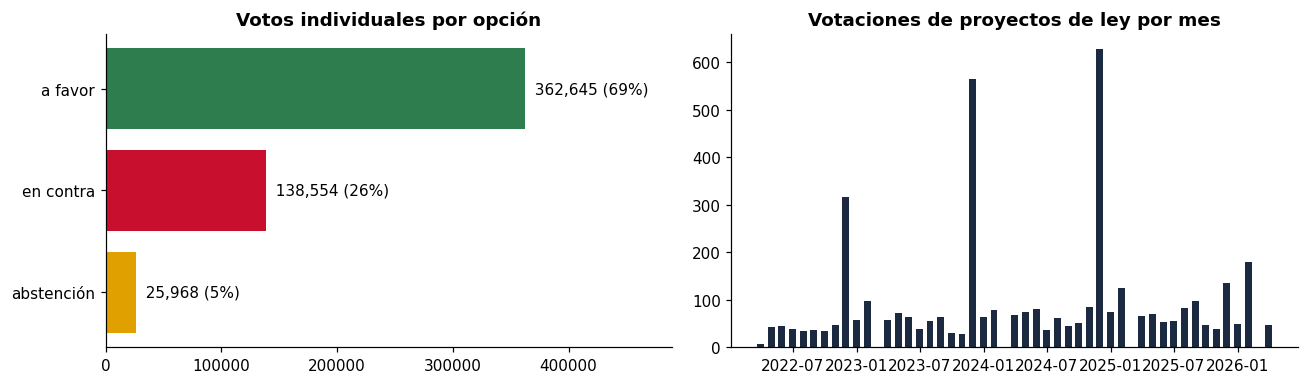

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
cnt = votos.y.value_counts().sort_index()
ax[0].barh(CLASES[::-1], cnt.values[::-1], color=[C_ABS, C_NO, C_SI])
for i, v in enumerate(cnt.values[::-1]):
    ax[0].text(v, i, f"  {v:,} ({v / cnt.sum():.0%})", va="center")
ax[0].set_title("Votos individuales por opción"); ax[0].set_xlim(0, cnt.max() * 1.35)
mes = vot.set_index("fecha").resample("M").size()
ax[1].bar(mes.index, mes.values, width=20, color=C_TINTA)
ax[1].set_title("Votaciones de proyectos de ley por mes")
plt.tight_layout(); plt.savefig(FIG / "fig_distribucion.png"); plt.show()

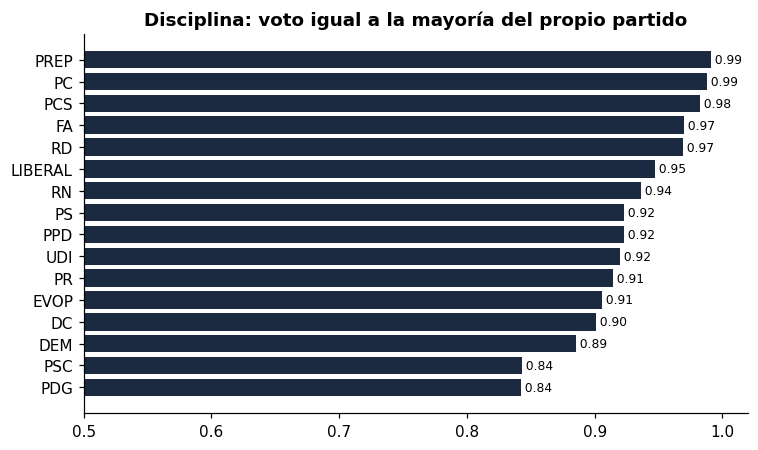

independientes y sin partido: 24.0% de los votos
votos de militantes distintos de la mayoría de su partido: 6.0%


In [6]:
# Disciplina: fracción de votos iguales a la mayoría del propio partido en esa votación (sin contarse a sí mismo)
def mayoria_sin_propio(df, clave):
    """Para cada voto, la opción más frecuente entre los demás del grupo `clave` en la misma votación."""
    c = pd.get_dummies(df.y).reindex(columns=[0, 1, 2], fill_value=0).astype(int)
    g = c.groupby([df.votacion_id, df[clave]]).transform("sum").values - c.values
    sin_dato = g.sum(1) == 0
    return np.where(sin_dato, -1, g.argmax(1))

votos["may_partido"] = mayoria_sin_propio(votos, "partido")
disc = votos[~votos.partido.isin(["IND", "SIN"]) & (votos.may_partido >= 0)]
tabla_disc = (disc.assign(igual=disc.y == disc.may_partido).groupby("partido")
              .agg(disciplina=("igual", "mean"), votos=("igual", "size"))
              .query("votos > 5000").sort_values("disciplina"))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(tabla_disc.index, tabla_disc.disciplina, color=C_TINTA)
for i, v in enumerate(tabla_disc.disciplina):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
ax.set_xlim(0.5, 1.02); ax.set_title("Disciplina: voto igual a la mayoría del propio partido")
plt.tight_layout(); plt.savefig(FIG / "fig_disciplina.png"); plt.show()
print(f"independientes y sin partido: {votos.partido.isin(['IND', 'SIN']).mean():.1%} de los votos")
tasa_ruptura = 1 - (disc.y == disc.may_partido).mean()
print(f"votos de militantes distintos de la mayoría de su partido: {tasa_ruptura:.1%}")

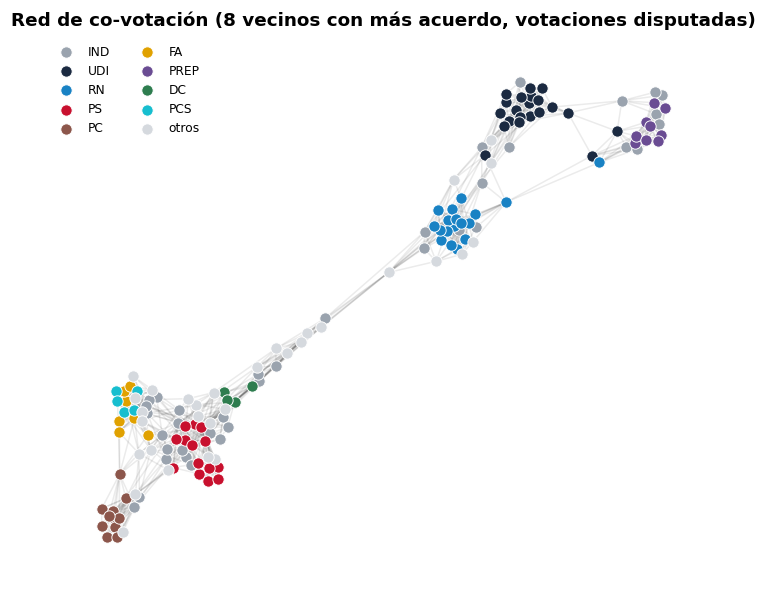

nodos 157, aristas 932, componentes 1
acuerdo medio entre diputados del mismo partido: 0.876 | de distinto partido: 0.499
homofilia de aristas (sin independientes): 0.633
modularidad: partición por partido 0.350 | Louvain 0.732 (7 comunidades)


In [7]:
# Red de co-votación: cada diputado se une a los 8 con que más coincide en votaciones disputadas
piv = votos[votos.votacion_id.isin(vot.votacion_id[vot.disputada])].pivot_table(
    index="diputado_id", columns="votacion_id", values="y", aggfunc="first")
piv = piv[piv.notna().sum(1) >= 200]
M = piv.values
iguales = sum((M == k).astype(float) @ (M == k).astype(float).T for k in range(3))
valido = (~np.isnan(M)).astype(float)
acuerdo = iguales / np.maximum(valido @ valido.T, 1)
np.fill_diagonal(acuerdo, np.nan)

partido_dip = votos.groupby("diputado_id").partido.agg(lambda s: s.mode().iloc[0])
ids = piv.index.tolist()
part_ids = partido_dip.reindex(ids).values
con_partido = ~np.isin(part_ids, ["IND", "SIN"])
par = con_partido[:, None] & con_partido[None, :]
mismo = part_ids[:, None] == part_ids[None, :]
acuerdo_intra = np.nanmean(acuerdo[mismo & par])
acuerdo_inter = np.nanmean(acuerdo[~mismo & par])

G = nx.Graph()
for d in ids:
    G.add_node(d, partido=partido_dip[d])
for i in range(len(ids)):
    for j in np.argsort(-np.nan_to_num(acuerdo[i], nan=-1))[:8]:
        G.add_edge(ids[i], ids[j], weight=acuerdo[i, j])

top_partidos = votos.partido.value_counts().index[:9].tolist()
paleta = ["#9AA3AE", "#1B2A41", "#1982C4", "#C8102E", "#8C564B", "#E0A100", "#6A4C93", "#2E7D4F", "#17BECF"]
color_partido = {p: paleta[i] for i, p in enumerate(top_partidos)}
homofilia = np.mean([G.nodes[u]["partido"] == G.nodes[v]["partido"] for u, v in G.edges()
                     if G.nodes[u]["partido"] not in ("IND", "SIN") and G.nodes[v]["partido"] not in ("IND", "SIN")])
from networkx.algorithms.community import modularity, louvain_communities
grupos = {}
for n, p in nx.get_node_attributes(G, "partido").items():
    grupos.setdefault(p, set()).add(n)
mod_partido = modularity(G, grupos.values())
comunidades = louvain_communities(G, seed=0)
mod_louvain = modularity(G, comunidades)
pos = nx.spring_layout(G, seed=3, k=0.12, iterations=300, weight="weight")
fig, ax = plt.subplots(figsize=(8, 6.5))
nx.draw_networkx_edges(G, pos, alpha=0.08, ax=ax)
for p in top_partidos + ["otros"]:
    ns = [n for n in G if (G.nodes[n]["partido"] == p) or (p == "otros" and G.nodes[n]["partido"] not in top_partidos)]
    nx.draw_networkx_nodes(G, pos, nodelist=ns, node_size=55, node_color="#D5D9DE" if p == "otros" else color_partido[p],
                           label=p, ax=ax, edgecolors="white", linewidths=0.6)
ax.legend(loc="best", fontsize=8, ncol=2, frameon=False); ax.axis("off")
ax.set_title("Red de co-votación (8 vecinos con más acuerdo, votaciones disputadas)")
plt.savefig(FIG / "fig_red_covotacion.png", facecolor="white"); plt.show()
print(f"nodos {G.number_of_nodes()}, aristas {G.number_of_edges():,}, componentes {nx.number_connected_components(G)}")
print(f"acuerdo medio entre diputados del mismo partido: {acuerdo_intra:.3f} | de distinto partido: {acuerdo_inter:.3f}")
print(f"homofilia de aristas (sin independientes): {homofilia:.3f}")
print(f"modularidad: partición por partido {mod_partido:.3f} | Louvain {mod_louvain:.3f} ({len(comunidades)} comunidades)")

## 3. Partición temporal y features

Se entrena con el pasado y se evalúa con el futuro: 70% de los días para train, 15% validación y 15% test.
Partir por día evita que votaciones del mismo proyecto y la misma sesión queden a ambos lados.

In [8]:
dias = np.sort(vot.fecha.dt.normalize().unique())
corte1, corte2 = dias[int(0.70 * len(dias))], dias[int(0.85 * len(dias))]
dia = vot.fecha.dt.normalize()
vot["split"] = np.where(dia < corte1, 0, np.where(dia < corte2, 1, 2))   # 0 train, 1 val, 2 test
vot["vidx"] = np.arange(len(vot))
vot["dia"] = pd.factorize(dia, sort=True)[0]
votos = votos.merge(vot[["votacion_id", "vidx", "split", "dia", "disputada"]], on="votacion_id")

dip_ids = np.sort(votos.diputado_id.unique())
didx = {d: i for i, d in enumerate(dip_ids)}
votos["didx"] = votos.diputado_id.map(didx)
for s, nombre in enumerate(["train", "val", "test"]):
    sub = vot[vot.split == s]
    print(f"{nombre:5s}: {sub.fecha.min():%Y-%m-%d} a {sub.fecha.max():%Y-%m-%d} | "
          f"{len(sub):,} votaciones | {(votos.split == s).sum():,} votos")

train: 2022-03-21 a 2024-11-13 | 2,603 votaciones | 338,784 votos
val  : 2024-11-14 a 2025-07-07 | 897 votaciones | 110,135 votos
test : 2025-07-08 a 2026-03-05 | 627 votaciones | 78,248 votos


In [9]:
# Texto: TF-IDF + SVD ajustados solo con train
tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), min_df=2, strip_accents="unicode", sublinear_tf=True)
tfidf.fit(vot.texto[vot.split == 0])
X_tfidf = tfidf.transform(vot.texto)
svd = TruncatedSVD(64, random_state=0).fit(X_tfidf[(vot.split == 0).values])
X_txt = svd.transform(X_tfidf)
X_txt = X_txt / (np.linalg.norm(X_txt, axis=1, keepdims=True) + 1e-9)

def one_hot(serie, min_freq=20):
    vc = serie[vot.split == 0].value_counts()
    cats = vc[vc >= min_freq].index
    return pd.get_dummies(serie.where(serie.isin(cats), "otro")).astype(float).values

X_vot = np.hstack([X_txt] + [one_hot(vot[c]) for c in
                   ["tipo_votacion", "tramite", "tramite_reglamentario", "quorum", "comision", "patrocinador", "iniciativa"]]
                  + [np.log1p(vot[["dias_ingreso"]].fillna(0).values) / 8])
print("features de votación:", X_vot.shape)

# Proyectos: texto del nombre + comisión + patrocinador
bol = vot.drop_duplicates("boletin")[["boletin", "nombre", "comision", "patrocinador", "iniciativa"]].reset_index(drop=True)
bidx = {b: i for i, b in enumerate(bol.boletin)}
Xp_txt = svd.transform(tfidf.transform(bol.nombre.fillna("")))
Xp_txt = Xp_txt / (np.linalg.norm(Xp_txt, axis=1, keepdims=True) + 1e-9)
X_proy = np.hstack([Xp_txt, pd.get_dummies(bol.iniciativa).astype(float).values])
vot["pidx"] = vot.boletin.map(bidx)

# Diputados: partido modal (one-hot), sexo
part_dip = partido_dip.reindex(dip_ids).fillna("SIN")
partidos = sorted(part_dip.unique())
X_dip = np.hstack([pd.get_dummies(part_dip).reindex(columns=partidos, fill_value=0).astype(float).values,
                   (dips.set_index("diputado_id").sexo.reindex(dip_ids) == "Femenino").astype(float).values[:, None]])
comisiones = sorted(bol.comision.unique())
print("diputados", X_dip.shape, "| proyectos", X_proy.shape, "| partidos", len(partidos), "| comisiones", len(comisiones))

features de votación: (4127, 116)
diputados (157, 24) | proyectos (675, 66) | partidos 23 | comisiones 30


### Aristas entre votaciones (el componente nuevo)

Una votación nueva no tiene votos, así que en un grafo sin más aristas el modelo no tiene por dónde traer información
de quién votó qué. Se agregan dos relaciones de votación a votación, siempre desde días **anteriores** hacia la
votación (nunca al revés), para no mirar el futuro:

- `similar`: las 10 votaciones más parecidas por texto (coseno sobre TF-IDF + SVD).
- `mismo_proyecto`: hasta 10 votaciones anteriores del mismo proyecto (por ejemplo, la votación en general antes de
  las votaciones en particular).

Si los votos de esas votaciones están en el grafo, viajan en dos saltos hasta la votación nueva:
diputado → votación pasada → votación nueva.

In [10]:
dia_arr = vot.dia.values
K_SIM = 10
S = (X_txt @ X_txt.T).astype(np.float32)
S[dia_arr[None, :] >= dia_arr[:, None]] = -np.inf
vecinos = np.argsort(-S, axis=1)[:, :K_SIM]
val_vec = np.take_along_axis(S, vecinos, 1); del S
fin = np.isfinite(val_vec)
src_sim, dst_sim = vecinos[fin], np.repeat(np.arange(len(vot))[:, None], K_SIM, 1)[fin]
w_sim = val_vec[fin]

src_mp, dst_mp = [], []
for _, g in vot.groupby("pidx"):
    idx, d = g.vidx.values, g.dia.values
    for k in range(len(idx)):
        prev = idx[d < d[k]][-10:]
        src_mp += prev.tolist(); dst_mp += [idx[k]] * len(prev)
src_mp, dst_mp = np.array(src_mp, dtype=int), np.array(dst_mp, dtype=int)
print(f"aristas similar: {len(src_sim):,} (similitud media {w_sim.mean():.2f}) | aristas mismo_proyecto: {len(src_mp):,}")
i = vot.index[vot.split == 2][40]
print("\nejemplo de test:", vot.texto[i][:120])
for j in vecinos[i][:3]:
    print("  vecino:", vot.texto[j][:110])

aristas similar: 41,206 (similitud media 0.74) | aristas mismo_proyecto: 16,863

ejemplo de test: Modifica el Código del Trabajo en materia de trabajo nocturno de mujeres embarazadas y personas que tengan bajo cuidado 
  vecino: Modifica el Código del Trabajo y otros cuerpos legales, en materia de prevención, investigación y sanción del 
  vecino: Modifica la ley N° 21.643, que modifica el Código del Trabajo y otros cuerpos legales, en materia de prevenció
  vecino: Modifica el Código del Trabajo para regular un permiso especial para quien acompañe a la madre por el nacimien


## 4. Protocolo de evaluación y baselines sin GNN

**Escenario B (principal).** Se predicen las votaciones de cada día de test conociendo todos los votos de los días
anteriores y, además, el 50% de los votos de esa votación (al azar, semilla fija). Ningún modelo se reentrena: los
pesos se ajustan solo con train; lo que cambia día a día es el historial disponible.

**Escenario A, evaluación diaria.** Igual, pero sin ningún voto visible de la votación. Es lo que tendría alguien que
quiere anticipar la sesión de mañana.

**Escenario A, bloque (horizonte largo).** Todo test se predice de una vez, con historial hasta el último día de
validación. Es más difícil: hay votaciones a 8 meses de distancia.

Baselines del escenario B (con los mismos votos visibles que la GNN):

1. **Mayoría del partido**: la opción más votada entre los colegas visibles del propio partido; los independientes
   usan la sala visible. Es el baseline de 0.861 medido en la etapa de propuesta. Nunca predice una ruptura.
2. **Mayoría de co-votación**: la opción más votada entre los 8 diputados que más coinciden con él en train
   (ponderada por acuerdo), entre los visibles. No mira el partido.
3. **Partido; independientes por co-votación**: la regla 1 para militantes y la 2 para independientes.
4. **NOMINATE**: modelo de puntos ideales, el estándar en ciencia política para completar votaciones nominales.
   Se explica en su propia celda, más abajo.

En B se reporta accuracy, F1 macro, accuracy sobre votos sí/no y, en la sección 7, precisión y recall sobre los votos
fuera de línea.

Baselines del escenario A (todos con la misma información de historial que la GNN):

1. **Mayoritaria**: siempre "a favor".
2. **Partido × patrocinador**: el voto más frecuente del partido del diputado frente a proyectos del mismo patrocinador
   (Ejecutivo o partido del autor) en el historial. Es la lógica gobierno-oposición.
3. **k-NN de votaciones anteriores**: lo que votó el mismo diputado en las votaciones anteriores del mismo proyecto y
   en las 10 más parecidas por texto (los mismos vecinos que usan las aristas de la GNN).
4. **Gradient boosting con historial**: HistGradientBoosting con diputado, partido, patrocinador, comisión, tipo,
   trámite, quórum, 16 componentes de texto y los conteos del k-NN como features. Se entrena con train + validación.

In [11]:
from scipy.sparse import csr_matrix

def metricas(y, p):
    return {"acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}

def visibles(df, r, seed):
    """Marca al azar una fracción r de los votos como visibles (escenario B)."""
    return np.random.default_rng(seed).random(len(df)) < r

test = votos[votos.split == 2].reset_index(drop=True)
hist = votos[votos.split < 2]
res_A, res_Abloque, res_B = {}, {}, {}

# Conteos de historial por (diputado, votación): votos del diputado en las votaciones vecinas
NV = len(vot)
W_txt = csr_matrix((w_sim, (dst_sim, src_sim)), shape=(NV, NV))
W_mp = csr_matrix((np.ones(len(src_mp)), (dst_mp, src_mp)), shape=(NV, NV))
def conteos(Ymat):
    """Devuelve dos arreglos (diputados x votaciones x 3): por texto y por mismo proyecto."""
    Y1 = [(Ymat == k).astype(float) for k in range(3)]
    txt = np.stack([(W_txt @ y.T).T for y in Y1], -1)
    mp = np.stack([(W_mp @ y.T).T for y in Y1], -1)
    return txt, mp

Ymat = np.full((len(dip_ids), NV), -1)
Ymat[votos.didx, votos.vidx] = votos.y
Ymat_bloque = Ymat.copy(); Ymat_bloque[:, vot.vidx[vot.split == 2]] = -1
CT, CM = conteos(Ymat)                 # diario: todo lo anterior al día es conocido
CT_b, CM_b = conteos(Ymat_bloque)      # bloque: solo hasta validación

def knn(df, CT, CM):
    s = 2 * CM[df.didx, df.vidx] + CT[df.didx, df.vidx]
    return np.where(s.sum(1) > 0, s.argmax(1), 0)

# Partido x patrocinador con historial acumulado por día
vp = votos.merge(vot[["vidx", "patrocinador"]], on="vidx")
def mayoria_acumulada(claves, objetivo, dia_obj):
    cnt = (vp.groupby(["dia"] + claves + ["y"]).size().unstack("y", fill_value=0)
           .reindex(columns=[0, 1, 2], fill_value=0))
    cnt.columns = ["c0", "c1", "c2"]
    acum = cnt.groupby(level=claves).cumsum().reset_index().sort_values("dia")
    obj = objetivo[claves].assign(dia=dia_obj).reset_index().sort_values("dia")
    m = pd.merge_asof(obj, acum, on="dia", by=claves, allow_exact_matches=False).set_index("index").sort_index()
    c = m[["c0", "c1", "c2"]].fillna(0).values
    return np.where(c.sum(1) > 0, c.argmax(1), -1)

tp = test.merge(vot[["vidx", "patrocinador"]], on="vidx", how="left")
def partido_patrocinador(dia_obj):
    p = mayoria_acumulada(["partido", "patrocinador"], tp, dia_obj)
    p2 = mayoria_acumulada(["partido"], tp, dia_obj)
    return np.where(p >= 0, p, np.where(p2 >= 0, p2, 0))

primer_dia_test = vot.dia[vot.split == 2].min()
pred_pp = partido_patrocinador(tp.dia.values)
res_A["Mayoritaria"] = res_Abloque["Mayoritaria"] = metricas(test.y, np.zeros(len(test), int))
res_A["Partido × patrocinador"] = metricas(test.y, pred_pp)
res_Abloque["Partido × patrocinador"] = metricas(test.y, partido_patrocinador(primer_dia_test))
res_A["k-NN votaciones anteriores"] = metricas(test.y, knn(test, CT, CM))
res_Abloque["k-NN votaciones anteriores"] = metricas(test.y, knn(test, CT_b, CM_b))

# Gradient boosting con historial
cat_cols = ["didx", "partido", "patrocinador", "comision", "tipo_votacion", "tramite", "quorum", "iniciativa"]
cats = {c: pd.Categorical(votos[c] if c in votos else vot[c]).categories for c in cat_cols}
def tabla_gb(df, CT, CM):
    t = df[["didx", "partido", "vidx"]].merge(vot[["vidx"] + cat_cols[2:]], on="vidx", how="left")
    cod = np.column_stack([pd.Categorical(t[c], categories=cats[c]).codes for c in cat_cols]).astype(float)
    cod[cod < 0] = np.nan
    return np.hstack([cod, X_txt[t.vidx.values, :16], CT[df.didx, df.vidx], CM[df.didx, df.vidx]])
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, categorical_features=list(range(len(cat_cols))),
                                    random_state=0)
gb.fit(tabla_gb(hist, CT, CM), hist.y)
res_A["Gradient boosting + historial"] = metricas(test.y, gb.predict(tabla_gb(test, CT, CM)))
res_Abloque["Gradient boosting + historial"] = metricas(test.y, gb.predict(tabla_gb(test, CT_b, CM_b)))

# B: mayoría del partido entre los visibles
def baseline_partido_visible(df, vis):
    d = df.copy(); d["vis"] = vis
    c = pd.get_dummies(d.y).reindex(columns=[0, 1, 2], fill_value=0).astype(int).mul(d.vis, axis=0)
    gp = c.groupby([d.votacion_id, d.partido]).transform("sum").values
    gs = c.groupby(d.votacion_id).transform("sum").values
    usa_sala = d.partido.isin(["IND", "SIN"]).values | (gp.sum(1) == 0)
    return np.where(usa_sala, gs.argmax(1), gp.argmax(1)), ~d.vis.values

# B: co-votación. Vecinos = los 8 diputados con más acuerdo, calculado solo con train (lo usa también la GNN)
_tr = votos[votos.split == 0].pivot_table(index="didx", columns="vidx", values="y", aggfunc="first").reindex(range(len(dip_ids)))
_M = _tr.values
_ac = sum((_M == k).astype(float) @ (_M == k).astype(float).T for k in range(3)) / np.maximum(
    (~np.isnan(_M)).astype(float) @ (~np.isnan(_M)).astype(float).T, 1)
np.fill_diagonal(_ac, -1)
A_COV_np = np.zeros_like(_ac)
for i, fila in enumerate(_ac):
    j = np.argsort(-fila)[:8]
    A_COV_np[i, j] = np.maximum(fila[j], 0)

def baseline_covotacion(df, vis, solo_indep=False):
    """Mayoría ponderada de los vecinos de co-votación visibles; si no hay ninguno visible, la regla del partido.
    Con solo_indep=True se aplica solo a independientes y el resto usa la mayoría del partido."""
    Yv = np.full((len(dip_ids), NV), -1)
    d, v = df.didx.values, df.vidx.values
    Yv[d[vis], v[vis]] = df.y.values[vis]
    cnt = np.stack([A_COV_np @ (Yv == k) for k in range(3)], -1)[d, v]
    p_part, ocultos = baseline_partido_visible(df, vis)
    p = np.where(cnt.sum(1) > 0, cnt.argmax(1), p_part)
    if solo_indep:
        p = np.where(df.partido.isin(["IND", "SIN"]).values, p, p_part)
    return p, cnt, ocultos

def metricas_B(y, p):
    """Como `metricas`, más la accuracy sobre los votos que son sí o no (NOMINATE no predice abstenciones)."""
    sn = y < 2
    return {**metricas(y, p), "acc_sino": accuracy_score(y[sn], p[sn])}

vis_test = visibles(test, 0.5, seed=123)
pb, oc = baseline_partido_visible(test, vis_test)
pcov, cnt_cov, _ = baseline_covotacion(test, vis_test)
pmix, _, _ = baseline_covotacion(test, vis_test, solo_indep=True)
res_B["Mayoría del partido (visibles)"] = metricas_B(test.y.values[oc], pb[oc])
res_B["Mayoría de co-votación (visibles)"] = metricas_B(test.y.values[oc], pcov[oc])
res_B["Partido; independientes por co-votación"] = metricas_B(test.y.values[oc], pmix[oc])
print("B (principal)\n", pd.DataFrame(res_B).T.round(3), "\n\nA diario\n", pd.DataFrame(res_A).T.round(3),
      "\n\nA bloque\n", pd.DataFrame(res_Abloque).T.round(3))

B (principal)
                                            acc     f1  acc_sino
Mayoría del partido (visibles)           0.872  0.707     0.899
Mayoría de co-votación (visibles)        0.921  0.759     0.947
Partido; independientes por co-votación  0.913  0.756     0.939 

A diario
                                  acc     f1
Mayoritaria                    0.662  0.266
Partido × patrocinador         0.676  0.339
k-NN votaciones anteriores     0.729  0.463
Gradient boosting + historial  0.744  0.475 

A bloque
                                  acc     f1
Mayoritaria                    0.662  0.266
Partido × patrocinador         0.666  0.323
k-NN votaciones anteriores     0.720  0.460
Gradient boosting + historial  0.742  0.474


### Baseline de puntos ideales: NOMINATE

Lo sugirió el profesor en el feedback de la propuesta: NOMINATE (Poole y Rosenthal) es el modelo estándar para
completar matrices de votaciones nominales. Cada diputado $i$ tiene un punto ideal $x_i$ en un espacio de $K$
dimensiones, dentro del círculo unitario. Cada votación $j$ tiene dos resultados: el del sí, en $z_j - \delta_j$, y el
del no, en $z_j + \delta_j$. La utilidad de cada resultado decae como una gaussiana de la distancia y el voto sale de
un probit:

$$P(\text{sí}_{ij}) = \Phi\Big(\beta\big[e^{-\frac12\sum_k w_k^2 (x_{ik} - z_{jk} + \delta_{jk})^2}
  - e^{-\frac12\sum_k w_k^2 (x_{ik} - z_{jk} - \delta_{jk})^2}\big]\Big)$$

con $w_1 = 0.5$ fijo, como en W-NOMINATE. Se usan $K = 2$ dimensiones, el estándar del método; la sensibilidad a $K$
está más abajo.

Es una implementación propia en PyTorch por máxima verosimilitud con Adam, no el paquete `wnominate` de R. Diferencias
con W-NOMINATE: estima todo junto por gradiente en vez de alternar entre diputados y votaciones, no descarta las
votaciones casi unánimes y parte de la SVD de la matriz de votos en vez de la matriz de acuerdo.

Las abstenciones se tratan como datos faltantes, igual que en NOMINATE: el modelo solo predice sí o no. Por eso en el
escenario B se reporta también la accuracy sobre los votos sí/no. NOMINATE no sirve para el escenario A: sin ningún
voto de la votación no hay cómo ubicar su línea de corte.

Protocolo B, igual que los otros baselines: para cada día de test se ajusta el modelo con todos los votos de los días
anteriores más el 50% visible de las votaciones del día (partiendo del ajuste del día anterior) y se predicen los
votos ocultos.

In [12]:
V_D = torch.tensor(votos.didx.values, dtype=torch.long, device=DEVICE)
V_V = torch.tensor(votos.vidx.values, dtype=torch.long, device=DEVICE)
V_Y = torch.tensor(votos.y.values, dtype=torch.long, device=DEVICE)
V_SPLIT = torch.tensor(votos.split.values, dtype=torch.long, device=DEVICE)
V_DIA = torch.tensor(votos.dia.values, dtype=torch.long, device=DEVICE)

class Nominate(nn.Module):
    def __init__(self, x0):
        super().__init__()
        K = x0.shape[1]
        g = torch.Generator().manual_seed(0)
        self.x = nn.Parameter(x0.clone())
        self.z = nn.Parameter((0.1 * torch.randn(NV, K, generator=g)).to(DEVICE))
        self.delta = nn.Parameter((0.1 * torch.randn(NV, K, generator=g)).to(DEVICE))
        self.log_beta = nn.Parameter(torch.tensor(np.log(10.0), device=DEVICE))
        self.log_w = nn.Parameter(torch.full((K - 1,), np.log(0.5), device=DEVICE))

    def margen(self, d, v):
        w = torch.cat([torch.full((1,), 0.5, device=DEVICE), self.log_w.exp()])
        x, z, dl = self.x[d], self.z[v], self.delta[v]
        u_si = torch.exp(-0.5 * ((w * (x - z + dl)) ** 2).sum(1))
        u_no = torch.exp(-0.5 * ((w * (x - z - dl)) ** 2).sum(1))
        return self.log_beta.exp() * (u_si - u_no)

    @torch.no_grad()
    def proyectar(self):
        for p in (self.x, self.z):
            p.div_(p.norm(dim=1, keepdim=True).clamp(min=1.0))

SINO = V_Y < 2
def ajustar_nominate(m, mascara, pasos, lr=0.05):
    m_ = mascara & SINO
    d, v, s = V_D[m_], V_V[m_], 1.0 - 2.0 * V_Y[m_].float()     # +1 sí, -1 no
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    for _ in range(pasos):
        loss = -torch.special.log_ndtr(s * m.margen(d, v)).mean()
        opt.zero_grad(); loss.backward(); opt.step(); m.proyectar()
    return loss.item()

def nominate_inicial(K, mascara, pasos=1500):
    """Puntos iniciales desde la SVD de la matriz diputado x votación (+1 sí, -1 no, 0 sin dato) y ajuste completo."""
    m_ = mascara & SINO
    M = torch.zeros(len(dip_ids), NV, device=DEVICE)
    M[V_D[m_], V_V[m_]] = 1.0 - 2.0 * V_Y[m_].float()
    U, S_, _ = torch.linalg.svd(M - M.mean(0, keepdim=True), full_matrices=False)
    x0 = U[:, :K] * S_[:K]
    m = Nominate(x0 / x0.norm(dim=1).max()).to(DEVICE)
    ajustar_nominate(m, mascara, pasos)
    return m

def nominate_B(split, r, K=2, seed=123, pasos_dia=150):
    """Escenario B día a día. Devuelve (y, P) de los votos ocultos del split, en el orden de votos[votos.split == split];
    P tiene columnas (sí, no, abstención) con abstención siempre 0."""
    obj = V_SPLIT == split
    idx = torch.nonzero(obj).squeeze(1)
    vis = torch.zeros_like(obj)
    vis[idx[torch.tensor(visibles(votos[votos.split == split], r, seed), device=DEVICE)]] = True
    m = nominate_inicial(K, V_SPLIT < split)
    p_si = torch.zeros(len(obj), device=DEVICE)
    for d in torch.unique(V_DIA[obj]):
        ajustar_nominate(m, (V_DIA < d) | (vis & (V_DIA == d)), pasos_dia)
        tgt = obj & (V_DIA == d) & ~vis
        with torch.no_grad():
            p_si[tgt] = torch.special.ndtr(m.margen(V_D[tgt], V_V[tgt]))
    oc_ = (obj & ~vis)[idx]
    p = p_si[idx][oc_].cpu().numpy()
    return V_Y[idx][oc_].cpu().numpy(), np.stack([p, 1 - p, np.zeros_like(p)], 1)

t0 = time.time()
y_nom, P_nom = nominate_B(2, 0.5)
assert (y_nom == test.y.values[oc]).all()
res_B["NOMINATE (2 dimensiones)"] = metricas_B(y_nom, P_nom.argmax(1))
print(f"NOMINATE en test: {time.time() - t0:.0f} s")
print(pd.DataFrame(res_B).T.round(3))

NOMINATE en test: 81 s
                                           acc     f1  acc_sino
Mayoría del partido (visibles)           0.872  0.707     0.899
Mayoría de co-votación (visibles)        0.921  0.759     0.947
Partido; independientes por co-votación  0.913  0.756     0.939
NOMINATE (2 dimensiones)                 0.919  0.620     0.960


In [13]:
# Sensibilidad al número de dimensiones (validación y test). K = 2 se fijó antes de mirar estos números.
y_nom_val, P_nom_val = nominate_B(1, 0.5)
sens_K = []
for K in [1, 2, 3]:
    fila = {"K": K}
    for nombre_s, s in [("val", 1), ("test", 2)]:
        y_, P_ = (y_nom_val, P_nom_val) if (K == 2 and s == 1) else (y_nom, P_nom) if K == 2 else nominate_B(s, 0.5, K=K)
        fila[f"{nombre_s}_acc"] = accuracy_score(y_, P_.argmax(1))
        fila[f"{nombre_s}_acc_sino"] = accuracy_score(y_[y_ < 2], P_.argmax(1)[y_ < 2])
    sens_K.append(fila)
tabla_K = pd.DataFrame(sens_K).set_index("K")
tabla_K.round(4)

,val_acc,val_acc_sino,test_acc,test_acc_sino
K,,,,
1,0.8778,0.9272,0.9046,0.9457
2,0.8896,0.9396,0.9186,0.9604
3,0.8942,0.9445,0.9126,0.9541


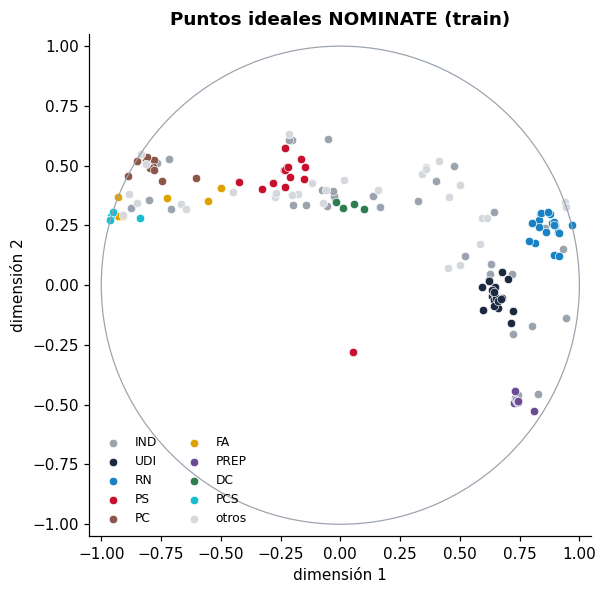

beta 25.4 | w2 1.49


In [14]:
# Puntos ideales estimados solo con train. Se usan también como feature de los diputados en la GNN (sección 5).
nom_train = nominate_inicial(2, V_SPLIT == 0)
X_IDEAL = nom_train.x.detach().cpu().numpy()
fig, ax = plt.subplots(figsize=(7, 5.5))
for p in top_partidos + ["otros"]:
    m = part_dip.isin([p]).values if p != "otros" else ~part_dip.isin(top_partidos).values
    ax.scatter(X_IDEAL[m, 0], X_IDEAL[m, 1], s=30, color="#D5D9DE" if p == "otros" else color_partido[p], label=p,
               edgecolors="white", linewidths=0.4)
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=C_GRIS, lw=0.8))
ax.set_aspect("equal"); ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
ax.legend(fontsize=8, ncol=2, frameon=False, loc="lower left")
ax.set_xlabel("dimensión 1"); ax.set_ylabel("dimensión 2")
ax.set_title("Puntos ideales NOMINATE (train)")
plt.tight_layout(); plt.savefig(FIG / "fig_puntos_ideales.png"); plt.show()
print(f"beta {nom_train.log_beta.exp().item():.1f} | w2 {nom_train.log_w.exp().item():.2f}")

## 5. Grafo heterogéneo y modelo

**Nodos**: diputado, votación, proyecto, partido, comisión.

**Aristas** (las que unen tipos distintos tienen además su inversa):

| relación | de → a | qué dice |
|---|---|---|
| `si`, `no`, `abs` | diputado → votación | voto observado, una relación por opción |
| `milita` | diputado → partido | partido modal en el período |
| `autor` | diputado → proyecto | autoría de mociones |
| `de` | votación → proyecto | a qué proyecto pertenece la votación |
| `en` | proyecto → comisión | sufijo del boletín |
| `similar` | votación pasada → votación | 10 vecinos por texto |
| `mismo_proyecto` | votación pasada → votación | votaciones anteriores del mismo proyecto |

**Modelo**: R-GCN de dos capas. Cada relación tiene su propia transformación (`SAGEConv` con agregación media; sumado
sobre relaciones equivale a la normalización $1/|N_r(i)|$ de R-GCN más un término propio), con conexión residual,
LayerNorm y dropout.

**Extensión: decoder con caminos tipados.** Un R-GCN calcula $h_v$ promediando a todos los que votaron en las
votaciones vecinas, así que pierde qué votó *este* diputado en ellas. Es el problema conocido de las GNN en predicción
de enlaces: las representaciones de cada nodo no ven la estructura del par (por eso existen SEAL o NBFNet). La extensión
cuenta, para cada par (diputado $d$, votación $v$), los caminos de 2 saltos que los unen, separados por opción de voto:

- $d \to u \to v$ con $u$ una votación pasada `similar` o del `mismo_proyecto`: qué votó $d$ en votaciones parecidas.
- $d \to d' \to v$ con $d'$ un colega de bancada: qué están votando sus colegas en esta votación (solo hay en B).
- $d \to d' \to v$ con $d'$ uno de los 8 diputados que más coinciden con $d$ en train: lo mismo, y sirve para los
  independientes (solo hay en B).

Solo se cuentan aristas visibles, así que el decoder nunca ve un voto oculto. El voto sale de un MLP sobre
$[h_d, h_v, h_d \odot h_v, |h_d - h_v|, \text{caminos}(d, v)]$. La pérdida es entropía cruzada con peso 1.5 para la
abstención (elegido en validación: sube el F1 macro casi sin costo en accuracy).

**Entrenamiento que imita la prueba.** En cada época se esconde el 30% de las votaciones de train. A la mitad no se le
deja ningún voto visible (escenario A); a la otra mitad se le deja visible una fracción al azar entre 10% y 80%
(escenario B). Los votos escondidos son las etiquetas y los visibles son aristas. Una arista de voto nunca es a la vez
mensaje y etiqueta. La mejor época se elige con validación (A en bloque + B), cada 5 épocas.

In [15]:
NT = {"diputado": len(dip_ids), "votacion": len(vot), "proyecto": len(bol), "partido": len(partidos),
      "comision": len(comisiones)}
# Los diputados llevan además sus puntos ideales NOMINATE (2 columnas al final, estimados solo con train). Se probaron
# como feature y empeoraron la validación, así que el modelo principal las deja en cero (ablación en la sección 6).
X = {"diputado": torch.tensor(np.hstack([X_dip, X_IDEAL]), dtype=torch.float32),
     "votacion": torch.tensor(X_vot, dtype=torch.float32),
     "proyecto": torch.tensor(X_proy, dtype=torch.float32)}
X = {k: v.to(DEVICE) for k, v in X.items()}
pidx_part = {p: i for i, p in enumerate(partidos)}
cidx = {c: i for i, c in enumerate(comisiones)}

def tens(a, b):
    return torch.tensor(np.vstack([a, b]), dtype=torch.long, device=DEVICE)

aut = autores[autores.boletin.isin(bidx) & autores.diputado_id.isin(didx)]
ESTRUCT = {
    ("diputado", "milita", "partido"): tens(np.arange(len(dip_ids)), part_dip.map(pidx_part).values),
    ("diputado", "autor", "proyecto"): tens(aut.diputado_id.map(didx).values, aut.boletin.map(bidx).values),
    ("votacion", "de", "proyecto"): tens(vot.vidx.values, vot.pidx.values),
    ("proyecto", "en", "comision"): tens(np.arange(len(bol)), bol.comision.map(cidx).values),
    ("votacion", "similar", "votacion"): tens(src_sim, dst_sim),
    ("votacion", "mismo_proyecto", "votacion"): tens(src_mp, dst_mp),
}
print({k[1]: int(v.shape[1]) for k, v in ESTRUCT.items()})
print(f"aristas de voto disponibles: {len(votos):,}")

W_SIM = torch.sparse_coo_tensor(tens(dst_sim, src_sim), torch.tensor(w_sim, dtype=torch.float32, device=DEVICE),
                                (NT["votacion"], NT["votacion"])).coalesce()
W_MP = torch.sparse_coo_tensor(tens(dst_mp, src_mp), torch.ones(len(src_mp), device=DEVICE),
                               (NT["votacion"], NT["votacion"])).coalesce()

# Diputado-diputado: misma bancada (sin independientes) y 8 vecinos de co-votación calculados solo con train
A_PART = torch.tensor((part_dip.values[:, None] == part_dip.values[None, :])
                      & ~np.isin(part_dip.values, ["IND", "SIN"])[:, None], dtype=torch.float32, device=DEVICE)
A_PART.fill_diagonal_(0)
A_COV = torch.tensor(A_COV_np, dtype=torch.float32, device=DEVICE)   # los mismos vecinos del baseline de co-votación
N_CAM = 16

def caminos(mascara_msg, cfg):
    """Caminos tipados de 2 saltos que terminan en el par (votación v, diputado d), contados por opción de voto:

    - d -(voto k)-> votación pasada u -(similar)-> v
    - d -(voto k)-> votación pasada u -(mismo_proyecto)-> v
    - d -(bancada)-> colega d' -(voto k)-> v
    - d -(co-votación)-> vecino d' -(voto k)-> v

    Devuelve (votaciones x diputados x 16): por cada tipo de camino, la fracción por opción y el log del total.
    Solo usa los votos de `mascara_msg`, así que nunca ve votos ocultos."""
    d, v, y = V_D[mascara_msg], V_V[mascara_msg], V_Y[mascara_msg]
    if not cfg["tipos_voto"]:          # ablación: el camino no sabe qué opción se votó
        y = torch.zeros_like(y)
    Y = []
    for k in range(3):
        sel = y == k
        Y.append(torch.sparse_coo_tensor(torch.stack([v[sel], d[sel]]), torch.ones(int(sel.sum()), device=DEVICE),
                                         (NT["votacion"], NT["diputado"])).coalesce())
    feats = []
    for C in ([torch.sparse.mm(W_SIM, Yk).to_dense() for Yk in Y],
              [torch.sparse.mm(W_MP, Yk).to_dense() for Yk in Y],
              [torch.sparse.mm(Yk, A_PART.T) for Yk in Y],
              [torch.sparse.mm(Yk, A_COV.T) for Yk in Y]):
        C = torch.stack(C, -1)
        tot = C.sum(-1, keepdim=True)
        feats += [C / (tot + 1e-6), torch.log1p(tot)]
    if not cfg["similitud"]:
        feats[0], feats[1] = feats[0] * 0, feats[1] * 0
    if not cfg["mismo_proyecto"]:
        feats[2], feats[3] = feats[2] * 0, feats[3] * 0
    return torch.cat(feats, -1)

def aristas(mascara_msg, cfg):
    """Diccionario edge_index con los votos de `mascara_msg` como mensajes y la estructura según cfg."""
    ed = {}
    d, v, y = V_D[mascara_msg], V_V[mascara_msg], V_Y[mascara_msg]
    if cfg["tipos_voto"]:
        for k, rel in enumerate(["si", "no", "abs"]):
            m = y == k
            ed[("diputado", rel, "votacion")] = torch.stack([d[m], v[m]])
    else:
        ed[("diputado", "vota", "votacion")] = torch.stack([d, v])
    for (a, r, b), ei in ESTRUCT.items():
        if (r == "similar" and not cfg["similitud"]) or (r == "mismo_proyecto" and not cfg["mismo_proyecto"]):
            continue
        if r in ("autor", "en") and not cfg["autoria"]:
            continue
        ed[(a, r, b)] = ei
    for (a, r, b), ei in list(ed.items()):
        if a != b:
            ed[(b, "rev_" + r, a)] = ei.flip(0)
    return ed

class VotoGNN(nn.Module):
    def __init__(self, rels, hidden=64, capas=2, drop=0.3, usar_grafo=True, usar_caminos=True, usar_puntos=False):
        super().__init__()
        self.usar_caminos = usar_caminos
        # sin puntos ideales (el caso normal), las dos últimas columnas de los diputados quedan en cero
        mascara = torch.ones(X["diputado"].shape[1], device=DEVICE)
        if not usar_puntos:
            mascara[-X_IDEAL.shape[1]:] = 0
        self.register_buffer("mascara_dip", mascara)
        self.lin = nn.ModuleDict({t: nn.Linear(X[t].shape[1], hidden) for t in X})
        self.emb = nn.ModuleDict({t: nn.Embedding(NT[t], hidden) for t in ["diputado", "partido", "comision"]})
        n = capas if usar_grafo else 0
        self.convs = nn.ModuleList([HeteroConv({r: SAGEConv((-1, -1), hidden) for r in rels}, aggr="sum")
                                    for _ in range(n)])
        self.norm = nn.ModuleList([nn.ModuleDict({t: nn.LayerNorm(hidden) for t in NT}) for _ in range(n)])
        self.drop = nn.Dropout(drop)
        self.dec = nn.Sequential(nn.Linear(4 * hidden + (N_CAM if usar_caminos else 0), hidden), nn.ReLU(), nn.Dropout(drop),
                                 nn.Linear(hidden, 3))

    def codificar(self, ed):
        h = {}
        for t in NT:
            h[t] = 0
            if t in self.lin:
                h[t] = h[t] + self.lin[t](X[t] * self.mascara_dip if t == "diputado" else X[t])
            if t in self.emb:
                h[t] = h[t] + self.emb[t].weight
        for conv, norm in zip(self.convs, self.norm):
            out = conv(h, ed)
            h = {t: norm[t](h[t] + self.drop(F.relu(out[t]))) if t in out else h[t] for t in h}
        return h

    def forward(self, ed, d, v, cam=None):
        h = self.codificar(ed)
        hd, hv = h["diputado"][d], h["votacion"][v]
        z = [hd, hv, hd * hv, (hd - hv).abs()]
        if self.usar_caminos:
            z.append(cam[v, d])
        return self.dec(torch.cat(z, 1)), h

{'milita': 157, 'autor': 2036, 'de': 4127, 'en': 675, 'similar': 41206, 'mismo_proyecto': 16863}
aristas de voto disponibles: 527,167


In [16]:
@torch.no_grad()
def evaluar(modelo, cfg, split, r, modo="diario", seed=123):
    """Probabilidades para los votos ocultos del split, en el orden de votos[votos.split == split].

    modo="bloque": historial = splits anteriores. modo="diario": para cada día, historial = días anteriores.
    r > 0 deja visible esa fracción de los votos (misma partición que el baseline de partido)."""
    modelo.eval()
    obj = V_SPLIT == split
    idx = torch.nonzero(obj).squeeze(1)
    vis = torch.zeros_like(obj)
    if r > 0:
        vis[idx[torch.tensor(visibles(votos[votos.split == split], r, seed), device=DEVICE)]] = True
    ocultos = obj & ~vis
    pos = torch.full((len(obj),), -1, dtype=torch.long, device=DEVICE)
    pos[idx] = torch.arange(len(idx), device=DEVICE)
    P = torch.zeros(len(idx), 3, device=DEVICE)
    if modo == "bloque":
        grupos = [(V_SPLIT < split, ocultos, vis)]
    else:
        grupos = [(V_DIA < d, ocultos & (V_DIA == d), vis & (V_DIA == d)) for d in torch.unique(V_DIA[obj])]
    h = None
    for hist_m, tgt, vis_d in grupos:
        if tgt.any():
            msg = hist_m | vis_d
            logits, h = modelo(aristas(msg, cfg), V_D[tgt], V_V[tgt], caminos(msg, cfg) if cfg["caminos"] else None)
            P[pos[tgt]] = logits.softmax(1)
    oc_np = ocultos[idx].cpu().numpy()
    return V_Y[idx].cpu().numpy()[oc_np], P.cpu().numpy()[oc_np], oc_np, h

def entrenar(cfg, seed, epocas=None, verbose=False):
    epocas = epocas or cfg.get("epocas", 200)
    torch.manual_seed(seed); np.random.seed(seed)
    gen = torch.Generator().manual_seed(seed)
    rels = list(aristas(V_SPLIT == 0, cfg).keys())
    modelo = VotoGNN(rels, capas=cfg.get("capas", 2), usar_grafo=cfg["grafo"], usar_caminos=cfg["caminos"],
                     usar_puntos=cfg["puntos_ideales"]).to(DEVICE)
    with torch.no_grad():   # inicializa capas perezosas
        modelo(aristas(V_SPLIT == 0, cfg), V_D[:2], V_V[:2], caminos(V_SPLIT == 0, cfg) if cfg["caminos"] else None)
    opt = torch.optim.Adam(modelo.parameters(), lr=3e-3, weight_decay=1e-5)
    peso = torch.tensor(cfg.get("pesos", [1.0, 1.0, 1.0]), device=DEVICE)
    v_train = torch.tensor(vot.vidx[vot.split == 0].values, dtype=torch.long, device=DEVICE)
    mejor, estado, curva = -1, None, []
    for ep in range(1, epocas + 1):
        modelo.train()
        perm = v_train[torch.randperm(len(v_train), generator=gen).to(DEVICE)]
        n_obj = int(0.3 * len(perm))
        v_obj = perm[:n_obj]
        r_v = torch.zeros(len(vot), device=DEVICE)
        mitad = v_obj[n_obj // 2:]
        r_v[mitad] = 0.1 + 0.7 * torch.rand(len(mitad), generator=gen).to(DEVICE)
        es_obj = torch.zeros(len(vot), dtype=torch.bool, device=DEVICE); es_obj[v_obj] = True
        obj = es_obj[V_V] & (V_SPLIT == 0)
        vis = obj & (torch.rand(len(V_V), generator=gen).to(DEVICE) < r_v[V_V])
        etiqueta = obj & ~vis
        msg = ((V_SPLIT == 0) & ~obj) | vis
        logits, _ = modelo(aristas(msg, cfg), V_D[etiqueta], V_V[etiqueta], caminos(msg, cfg) if cfg["caminos"] else None)
        loss = F.cross_entropy(logits, V_Y[etiqueta], weight=peso)
        opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 0:
            yA, pA, _, _ = evaluar(modelo, cfg, 1, 0.0, modo="bloque")
            yB, pB, _, _ = evaluar(modelo, cfg, 1, 0.5, modo="bloque")
            accA, accB = accuracy_score(yA, pA.argmax(1)), accuracy_score(yB, pB.argmax(1))
            curva.append((ep, loss.item(), accA, accB))
            if accA + accB > mejor:
                mejor, estado = accA + accB, {k: v.detach().clone() for k, v in modelo.state_dict().items()}
            if verbose and ep % 25 == 0:
                print(f"  ép {ep:3d} | loss {loss.item():.3f} | val A {accA:.3f} | val B {accB:.3f}")
    modelo.load_state_dict(estado)
    return modelo, curva

# Hiperparámetros elegidos en validación (2 o 3 capas, 200 o 300 épocas, peso de la abstención 1, 1.5 o 2)
HP = dict(capas=2, epocas=200, pesos=[1.0, 1.0, 1.5])
CFG_BASE = dict(grafo=True, caminos=True, puntos_ideales=False, tipos_voto=True, similitud=True, mismo_proyecto=True,
                autoria=True, **HP)
CFG = {
    "R-GCN completo":                CFG_BASE,
    "sin caminos tipados":           {**CFG_BASE, "caminos": False},
    "sin message passing":           {**CFG_BASE, "grafo": False},
    "sin aristas votación-votación": {**CFG_BASE, "similitud": False, "mismo_proyecto": False},
    "sin autoría ni comisión":       {**CFG_BASE, "autoria": False},
    "voto sin tipo (homogéneo)":     {**CFG_BASE, "tipos_voto": False},
    "con puntos ideales como feature": {**CFG_BASE, "puntos_ideales": True},
    "MLP sin grafo":                 {**CFG_BASE, "grafo": False, "caminos": False},
}
print("hiperparámetros:", HP)

t0 = time.time()
m0, curva0 = entrenar(CFG["R-GCN completo"], 0, verbose=True)
print(f"una corrida: {time.time() - t0:.0f} s")

hiperparámetros: {'capas': 2, 'epocas': 200, 'pesos': [1.0, 1.0, 1.5]}


  ép  25 | loss 0.663 | val A 0.700 | val B 0.798


  ép  50 | loss 0.537 | val A 0.732 | val B 0.861


  ép  75 | loss 0.478 | val A 0.718 | val B 0.874


  ép 100 | loss 0.462 | val A 0.738 | val B 0.890


  ép 125 | loss 0.441 | val A 0.727 | val B 0.892


  ép 150 | loss 0.419 | val A 0.731 | val B 0.898


  ép 175 | loss 0.410 | val A 0.722 | val B 0.902


  ép 200 | loss 0.403 | val A 0.727 | val B 0.901
una corrida: 24 s


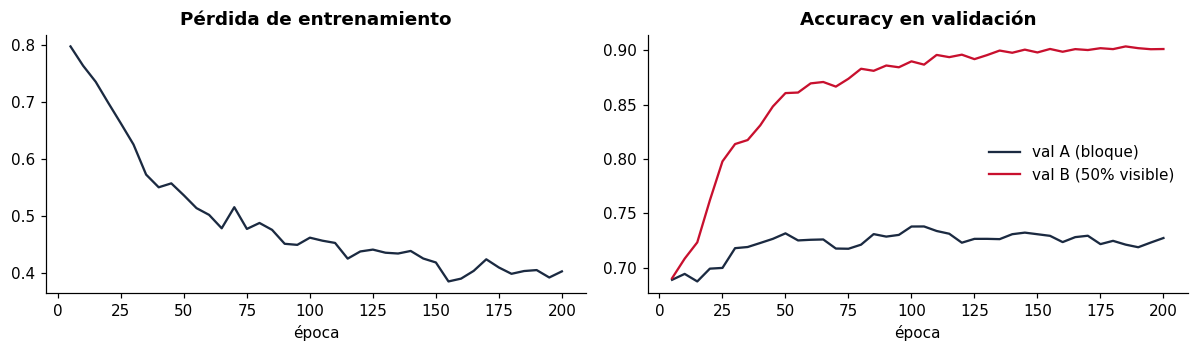

In [17]:
c = np.array(curva0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(c[:, 0], c[:, 1], color=C_TINTA); ax[0].set_title("Pérdida de entrenamiento"); ax[0].set_xlabel("época")
ax[1].plot(c[:, 0], c[:, 2], label="val A (bloque)", color=C_TINTA)
ax[1].plot(c[:, 0], c[:, 3], label="val B (50% visible)", color=C_GNN)
ax[1].set_title("Accuracy en validación"); ax[1].set_xlabel("época"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "fig_curvas_entrenamiento.png"); plt.show()

## 6. Resultados en test: 5 semillas por configuración

Media ± desviación estándar entre semillas. Los baselines son deterministas.

**R-GCN + NOMINATE (escenario B).** NOMINATE separa muy bien el sí del no (es el mejor baseline en votos sí/no), pero no
predice abstenciones; la R-GCN sí las predice. La combinación usa la probabilidad de abstención de la R-GCN y, entre sí y
no, una media geométrica de las probabilidades condicionales de los dos modelos, con peso $b$ para NOMINATE:

$$P(\text{abs}) = p^{\text{GNN}}_{\text{abs}}, \qquad
  P(k) \propto (1 - p^{\text{GNN}}_{\text{abs}})\,\big(q^{\text{NOM}}_k\big)^{b}\big(q^{\text{GNN}}_k\big)^{1-b},\ k \in \{\text{sí}, \text{no}\}$$

$b \in \{0, 0.1, \dots, 1\}$ se elige por semilla con la accuracy de validación en B. No se reentrena nada.

Se probó también darle a la R-GCN los puntos ideales de NOMINATE como feature de cada diputado: empeoró la validación
(queda como ablación, "con puntos ideales como feature").

In [18]:
def medir(y, p):
    return accuracy_score(y, p.argmax(1)), f1_score(y, p.argmax(1), average="macro")

corridas = {}
for nombre, cfg in CFG.items():
    filas = []
    for s in SEMILLAS:
        m = m0 if (nombre == "R-GCN completo" and s == 0) else entrenar(cfg, s)[0]
        f = {"semilla": s}
        for esc, (modo, r) in {"A": ("diario", 0.0), "Ab": ("bloque", 0.0), "B": ("diario", 0.5)}.items():
            y, p, _, _ = evaluar(m, cfg, 2, r, modo=modo)
            f[f"{esc}_acc"], f[f"{esc}_f1"] = medir(y, p)
            f[f"p{esc}"] = p
        f["B_sn"] = accuracy_score(y[y < 2], p.argmax(1)[y < 2])          # el último escenario del ciclo es B
        if nombre == "R-GCN completo":                                    # para elegir la combinación con NOMINATE
            f["pBval"] = evaluar(m, cfg, 1, 0.5)[1]
        f["modelo"] = m if nombre == "R-GCN completo" else None
        filas.append(f)
    corridas[nombre] = filas
    df = pd.DataFrame(filas)
    print(f"{nombre:31s} A {df.A_acc.mean():.3f}±{df.A_acc.std():.3f} (F1 {df.A_f1.mean():.3f}) | "
          f"A bloque {df.Ab_acc.mean():.3f}±{df.Ab_acc.std():.3f} | B {df.B_acc.mean():.3f}±{df.B_acc.std():.3f} "
          f"(F1 {df.B_f1.mean():.3f})", flush=True)

R-GCN completo                  A 0.765±0.005 (F1 0.513) | A bloque 0.764±0.006 | B 0.917±0.003 (F1 0.755)


sin caminos tipados             A 0.774±0.003 (F1 0.518) | A bloque 0.772±0.003 | B 0.890±0.003 (F1 0.660)


sin message passing             A 0.767±0.002 (F1 0.494) | A bloque 0.766±0.002 | B 0.910±0.002 (F1 0.740)


sin aristas votación-votación   A 0.768±0.001 (F1 0.513) | A bloque 0.767±0.001 | B 0.918±0.004 (F1 0.755)


sin autoría ni comisión         A 0.770±0.003 (F1 0.517) | A bloque 0.768±0.003 | B 0.919±0.003 (F1 0.758)


voto sin tipo (homogéneo)       A 0.772±0.008 (F1 0.508) | A bloque 0.772±0.008 | B 0.772±0.007 (F1 0.508)


con puntos ideales como feature A 0.768±0.004 (F1 0.514) | A bloque 0.766±0.004 | B 0.916±0.003 (F1 0.754)


MLP sin grafo                   A 0.775±0.003 (F1 0.500) | A bloque 0.775±0.003 | B 0.774±0.003 (F1 0.500)


In [19]:
def resumen(nombre, esc):
    df = pd.DataFrame(corridas[nombre])
    r = {"acc": df[f"{esc}_acc"].mean(), "acc_sd": df[f"{esc}_acc"].std(),
         "f1": df[f"{esc}_f1"].mean(), "f1_sd": df[f"{esc}_f1"].std()}
    if esc == "B":
        r["acc_sino"] = df.B_sn.mean()
    return r

# R-GCN + NOMINATE (escenario B). La R-GCN da la probabilidad de abstención; entre sí y no se combinan las dos
# probabilidades condicionales con una media geométrica de peso b para NOMINATE. b se elige por semilla en validación.
def hibrido(p_gnn, p_nom, b):
    p_abs = p_gnn[:, 2:3]
    q_gnn = p_gnn[:, :2] / p_gnn[:, :2].sum(1, keepdims=True).clip(1e-9)
    q = np.exp(b * np.log(p_nom[:, :2].clip(1e-6)) + (1 - b) * np.log(q_gnn.clip(1e-6)))
    return np.hstack([(1 - p_abs) * q / q.sum(1, keepdims=True), p_abs])

HIB = "R-GCN + NOMINATE"
y_val_oc = votos[votos.split == 1].y.values[~visibles(votos[votos.split == 1], 0.5, 123)]
filas_h = []
for f in corridas["R-GCN completo"]:
    b = max(np.round(np.linspace(0, 1, 11), 1), key=lambda b: accuracy_score(y_val_oc, hibrido(f["pBval"], P_nom_val, b).argmax(1)))
    p = hibrido(f["pB"], P_nom, b)
    yb = test.y.values[oc]
    filas_h.append({"semilla": f["semilla"], "b": b, "B_acc": accuracy_score(yb, p.argmax(1)),
                    "B_f1": f1_score(yb, p.argmax(1), average="macro"),
                    "B_sn": accuracy_score(yb[yb < 2], p.argmax(1)[yb < 2]), "pB": p})
corridas[HIB] = filas_h
print(pd.DataFrame(filas_h)[["semilla", "b", "B_acc", "B_f1", "B_sn"]].round(4))

def tabla(base, esc, modelos):
    return pd.DataFrame({**{k: {**v, "acc_sd": 0.0, "f1_sd": 0.0} for k, v in base.items()},
                         **{m: resumen(m, esc) for m in modelos}}).T

tabla_A = tabla(res_A, "A", ["MLP sin grafo", "R-GCN completo"])
tabla_Ab = tabla(res_Abloque, "Ab", ["MLP sin grafo", "R-GCN completo"])
tabla_B = tabla(res_B, "B", ["R-GCN completo", HIB])
tabla_abl = pd.DataFrame({k: {"A_acc": resumen(k, "A")["acc"], "A_f1": resumen(k, "A")["f1"],
                              "Ab_acc": resumen(k, "Ab")["acc"], "B_acc": resumen(k, "B")["acc"],
                              "B_f1": resumen(k, "B")["f1"], "B_acc_sino": resumen(k, "B")["acc_sino"]} for k in CFG}).T
print("Escenario B, 50% visible (principal)\n", tabla_B.round(3), "\n\nEscenario A, evaluación diaria\n", tabla_A.round(3),
      "\n\nEscenario A, bloque de 8 meses\n", tabla_Ab.round(3), "\n\nAblaciones (accuracy y F1 macro)\n", tabla_abl.round(3))

# Comparación pareada por semilla contra el mejor baseline de cada escenario
pareado = {}
for esc, base in [("B", res_B), ("A", res_A), ("Ab", res_Abloque)]:
    mejor = max(base, key=lambda k: base[k]["acc"])
    for modelo in (["R-GCN completo", HIB] if esc == "B" else ["R-GCN completo"]):
        dif = pd.DataFrame(corridas[modelo])[f"{esc}_acc"] - base[mejor]["acc"]
        pareado[esc if modelo == "R-GCN completo" else esc + "_hibrido"] = {
            "mejor_baseline": mejor, "dif_media": float(dif.mean()), "dif_min": float(dif.min()),
            "dif_max": float(dif.max()), "gana": int((dif > 0).sum())}
        print(f"{esc}: {modelo} menos '{mejor}' = {dif.mean():+.3f} (mín {dif.min():+.3f}, máx {dif.max():+.3f}); "
              f"gana en {(dif > 0).sum()} de {len(dif)} semillas")

   semilla    b   B_acc    B_f1    B_sn
0        0  0.3  0.9243  0.7585  0.9510
1        1  0.5  0.9247  0.7617  0.9506
2        2  0.4  0.9218  0.7497  0.9494
3        3  0.4  0.9234  0.7620  0.9487
4        4  0.4  0.9242  0.7625  0.9495
Escenario B, 50% visible (principal)
                                            acc     f1  acc_sino  acc_sd  f1_sd
Mayoría del partido (visibles)           0.872  0.707     0.899   0.000  0.000
Mayoría de co-votación (visibles)        0.921  0.759     0.947   0.000  0.000
Partido; independientes por co-votación  0.913  0.756     0.939   0.000  0.000
NOMINATE (2 dimensiones)                 0.919  0.620     0.960   0.000  0.000
R-GCN completo                           0.917  0.755     0.942   0.003  0.005
R-GCN + NOMINATE                         0.924  0.759     0.950   0.001  0.005 

Escenario A, evaluación diaria
                                  acc     f1  acc_sd  f1_sd
Mayoritaria                    0.662  0.266   0.000  0.000
Partido × patroci

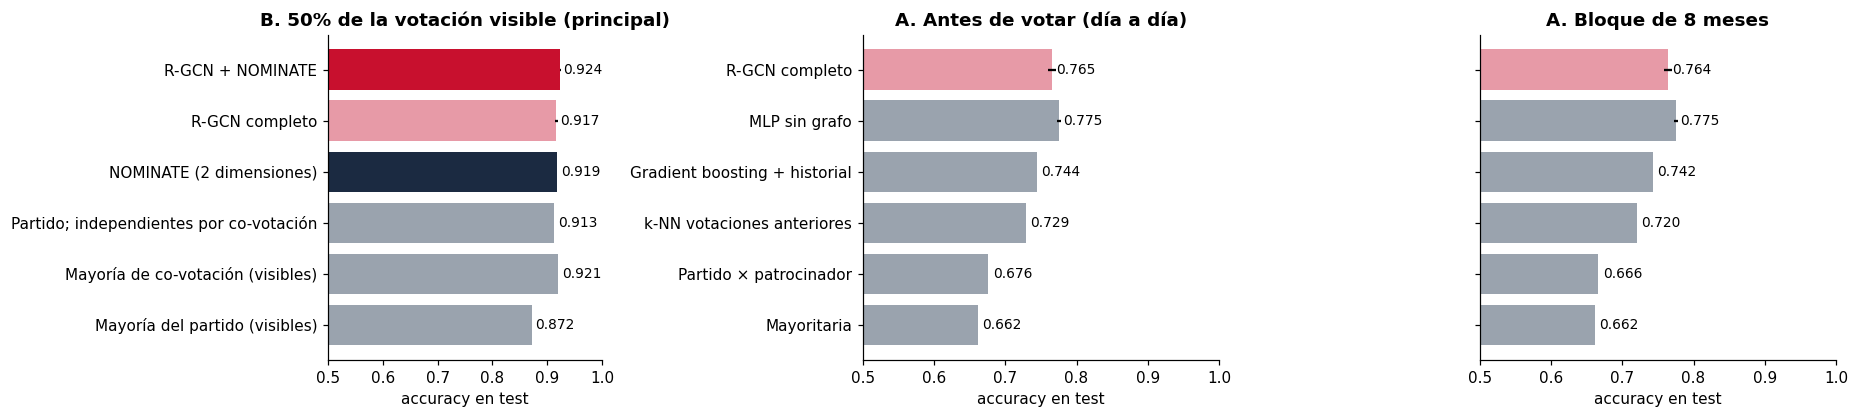

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
for a, t, titulo in [(axs[0], tabla_B, "B. 50% de la votación visible (principal)"),
                     (axs[1], tabla_A, "A. Antes de votar (día a día)"), (axs[2], tabla_Ab, "A. Bloque de 8 meses")]:
    col = [C_GNN if i == HIB else "#E79AA7" if i == "R-GCN completo" else C_TINTA if i.startswith("NOMINATE") else C_GRIS
           for i in t.index]
    a.barh(t.index, t.acc, xerr=t.acc_sd, color=col)
    for i, v in enumerate(t.acc):
        a.text(v + 0.006, i, f"{v:.3f}", va="center", fontsize=9)
    a.set_xlim(0.5, 1); a.set_title(titulo); a.set_xlabel("accuracy en test")
axs[2].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG / "fig_resultados.png"); plt.show()

### ¿Cuánto ayuda ver parte de la votación?

Los mismos modelos, evaluados día a día con distintas fracciones de votos visibles en test.

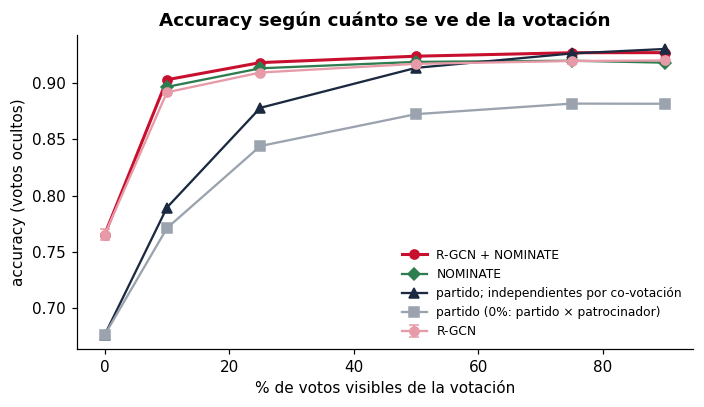

,visible,R-GCN + NOMINATE,R-GCN,NOMINATE,partido; indep. co-votación,partido
0,0.00,0.765,0.765,NaN,0.676,0.676
1,0.10,0.903,0.892,0.896,0.789,0.771
2,0.25,0.918,0.909,0.913,0.878,0.844
3,0.50,0.924,0.917,0.919,0.913,0.872
4,0.75,0.927,0.919,0.920,0.926,0.882
5,0.90,0.927,0.920,0.918,0.930,0.881


In [21]:
fracs = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9]
curva_gnn, curva_par, curva_mix, curva_nom, curva_hib = [], [], [], [], []
for r in fracs:
    evs = [evaluar(f["modelo"], CFG["R-GCN completo"], 2, r)[:2] for f in corridas["R-GCN completo"]]
    accs = [medir(y, p)[0] for y, p in evs]
    curva_gnn.append((np.mean(accs), np.std(accs)))
    if r > 0:   # NOMINATE necesita votos visibles; la combinación usa el b de cada semilla elegido con 50%
        y_r, P_r = (y_nom, P_nom) if r == 0.5 else nominate_B(2, r)
        curva_nom.append(accuracy_score(y_r, P_r.argmax(1)))
        curva_hib.append(np.mean([accuracy_score(y_r, hibrido(p, P_r, fh["b"]).argmax(1))
                                  for (_, p), fh in zip(evs, corridas[HIB])]))
    else:
        curva_nom.append(np.nan); curva_hib.append(curva_gnn[-1][0])
    if r > 0:
        vis_r = visibles(test, r, 123)
        pb_r, oc_r = baseline_partido_visible(test, vis_r)
        pm_r, _, _ = baseline_covotacion(test, vis_r, solo_indep=True)
        curva_par.append(accuracy_score(test.y[oc_r], pb_r[oc_r]))
        curva_mix.append(accuracy_score(test.y[oc_r], pm_r[oc_r]))
    else:
        curva_par.append(res_A["Partido × patrocinador"]["acc"])
        curva_mix.append(res_A["Partido × patrocinador"]["acc"])
cg = np.array(curva_gnn)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(np.array(fracs) * 100, curva_hib, color=C_GNN, marker="o", label="R-GCN + NOMINATE", lw=2)
ax.errorbar(np.array(fracs) * 100, cg[:, 0], yerr=cg[:, 1], color="#E79AA7", marker="o", label="R-GCN", capsize=3)
ax.plot(np.array(fracs) * 100, curva_nom, color=C_SI, marker="D", label="NOMINATE")
ax.plot(np.array(fracs) * 100, curva_mix, color=C_TINTA, marker="^", label="partido; independientes por co-votación")
ax.plot(np.array(fracs) * 100, curva_par, color=C_GRIS, marker="s", label="partido (0%: partido × patrocinador)")
ax.set_xlabel("% de votos visibles de la votación"); ax.set_ylabel("accuracy (votos ocultos)")
ax.legend(frameon=False, fontsize=8); ax.set_title("Accuracy según cuánto se ve de la votación")
plt.tight_layout(); plt.savefig(FIG / "fig_curva_visibles.png"); plt.show()
pd.DataFrame({"visible": fracs, "R-GCN + NOMINATE": curva_hib, "R-GCN": cg[:, 0], "NOMINATE": curva_nom,
              "partido; indep. co-votación": curva_mix, "partido": curva_par}).round(3)

### Subgrupos: ¿dónde gana el grafo?

- **Independientes**: sin partido, el baseline de partido no les sirve.
- **Díscolos**: votos distintos de la mayoría del propio partido en esa votación.
- **Disputadas**: votaciones con minoría de al menos 10%.
- **Abstenciones**: la clase minoritaria (recall).

Se usa el promedio de probabilidades de las 5 semillas.

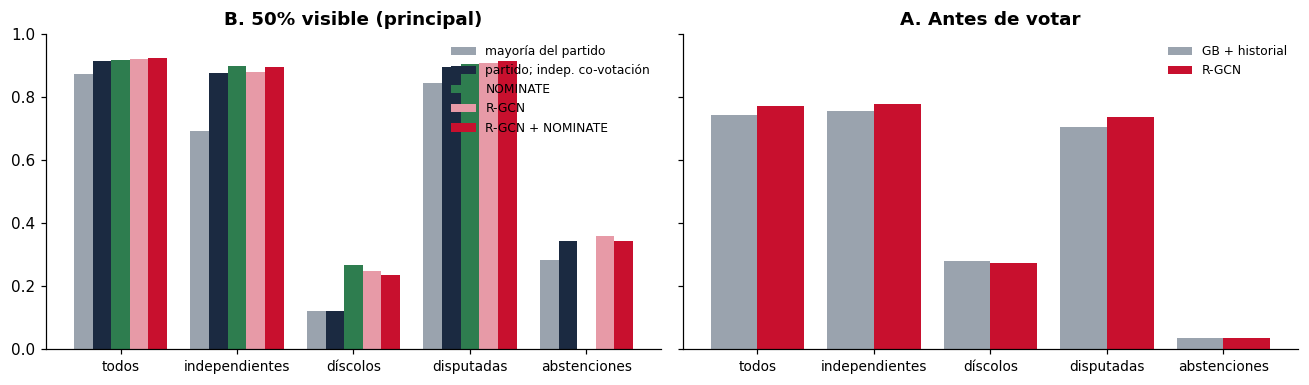

,n_A,A GB+historial,A R-GCN,n_B,B partido,B partido + co-votación,B NOMINATE,B R-GCN,B R-GCN + NOMINATE
subgrupo,,,,,,,,,
todos,78248,0.744,0.773,39137,0.872,0.913,0.919,0.920,0.925
independientes,17052,0.756,0.777,8653,0.691,0.877,0.898,0.879,0.895
díscolos,3003,0.279,0.274,1459,0.121,0.121,0.269,0.248,0.236
disputadas,63021,0.704,0.738,31558,0.846,0.897,0.905,0.909,0.914
abstenciones,3409,0.037,0.037,1701,0.284,0.344,0.000,0.361,0.343


In [22]:
pA_media = np.mean([f["pA"] for f in corridas["R-GCN completo"]], axis=0)
pB_media = np.mean([f["pB"] for f in corridas["R-GCN completo"]], axis=0)
pH_media = np.mean([f["pB"] for f in corridas[HIB]], axis=0)
predA, predB, predH = pA_media.argmax(1), pB_media.argmax(1), pH_media.argmax(1)
pred_gb = gb.predict(tabla_gb(test, CT, CM))
tB = test[oc].reset_index(drop=True)
indep = test.partido.isin(["IND", "SIN"]).values
discolo = ((test.may_partido >= 0) & (test.y != test.may_partido)).values & ~indep
sub = {
    "todos": np.ones(len(test), bool),
    "independientes": indep,
    "díscolos": discolo,
    "disputadas": test.disputada.values,
    "abstenciones": (test.y == 2).values,
}
filas = []
yt, yb = test.y.values, tB.y.values
for k, m in sub.items():
    mb = m[oc]
    filas.append({"subgrupo": k, "n_A": int(m.sum()),
                  "A GB+historial": np.mean(pred_gb[m] == yt[m]), "A R-GCN": np.mean(predA[m] == yt[m]),
                  "n_B": int(mb.sum()), "B partido": np.mean(pb[oc][mb] == yb[mb]),
                  "B partido + co-votación": np.mean(pmix[oc][mb] == yb[mb]),
                  "B NOMINATE": np.mean(P_nom.argmax(1)[mb] == yb[mb]), "B R-GCN": np.mean(predB[mb] == yb[mb]),
                  "B R-GCN + NOMINATE": np.mean(predH[mb] == yb[mb])})
tabla_sub = pd.DataFrame(filas).set_index("subgrupo")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
x = np.arange(len(tabla_sub))
for j, (c, col, lab) in enumerate([("B partido", C_GRIS, "mayoría del partido"),
                                   ("B partido + co-votación", C_TINTA, "partido; indep. co-votación"),
                                   ("B NOMINATE", C_SI, "NOMINATE"), ("B R-GCN", "#E79AA7", "R-GCN"),
                                   ("B R-GCN + NOMINATE", C_GNN, "R-GCN + NOMINATE")]):
    ax[0].bar(x + (j - 2) * 0.16, tabla_sub[c], 0.16, color=col, label=lab)
ax[1].bar(x - 0.2, tabla_sub["A GB+historial"], 0.4, color=C_GRIS, label="GB + historial")
ax[1].bar(x + 0.2, tabla_sub["A R-GCN"], 0.4, color=C_GNN, label="R-GCN")
for a, titulo in [(ax[0], "B. 50% visible (principal)"), (ax[1], "A. Antes de votar")]:
    a.set_xticks(x); a.set_xticklabels(tabla_sub.index, fontsize=9); a.legend(frameon=False, fontsize=8)
    a.set_title(titulo); a.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIG / "fig_subgrupos.png"); plt.show()
tabla_sub.round(3)

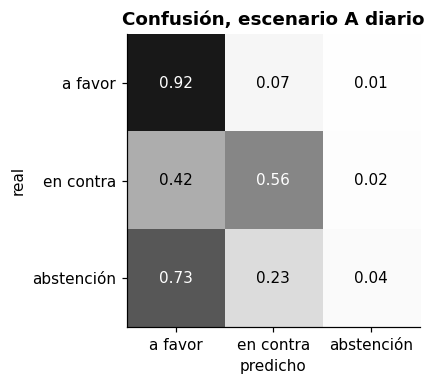

In [23]:
cm = confusion_matrix(test.y, predA, normalize="true")
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Greys", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels(CLASES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASES)
ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title("Confusión, escenario A diario")
plt.tight_layout(); plt.savefig(FIG / "fig_confusion_A.png"); plt.show()

## 7. ¿Quién se sale de la línea? Votos fuera de línea (escenario B)

El profesor pidió reportar precisión y recall sobre los votos fuera de línea además de la accuracy. Un voto fuera de
línea (en el código, **ruptura**) es un voto oculto de un militante distinto de la mayoría visible de su propio partido en esa votación.
Se consideran solo militantes con al menos un colega de bancada visible. La regla del partido nunca predice una
ruptura: acierta todo lo demás y falla justo en lo que interesa. Se mide:

- precisión, recall y F1 de las rupturas que marca cada modelo (predice una opción distinta de la mayoría visible del
  partido);
- average precision (AP), ordenando los votos por la probabilidad de no votar como el partido. Un orden al azar da AP
  igual a la tasa de rupturas.

Para la co-votación, el puntaje es la fracción del peso de los vecinos visibles que no votó como la mayoría del partido.

votos ocultos de militantes evaluados: 27,311 | rupturas: 1,428 (5.2%)
                                   precision  recall     f1     ap  marcados  \
Mayoría del partido (visibles)         0.000   0.000  0.000  0.052       0.0   
Mayoría de co-votación (visibles)      0.471   0.315  0.378  0.298     956.0   
NOMINATE (2 dimensiones)               0.394   0.410  0.402  0.285    1487.0   
sin caminos tipados                    0.276   0.455  0.343  0.243    2357.0   
sin message passing                    0.378   0.291  0.329  0.268    1101.2   
R-GCN completo                         0.406   0.314  0.354  0.308    1104.8   
R-GCN + NOMINATE                       0.441   0.320  0.371  0.348    1037.0   

                                   precision_sd  recall_sd  f1_sd  ap_sd  
Mayoría del partido (visibles)            0.000      0.000  0.000  0.000  
Mayoría de co-votación (visibles)         0.000      0.000  0.000  0.000  
NOMINATE (2 dimensiones)                  0.000      0.000  0.0

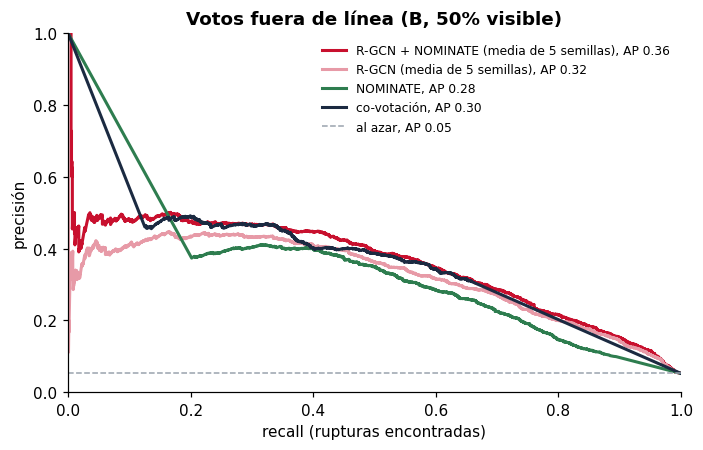

In [24]:
from sklearn.metrics import average_precision_score, precision_recall_curve

d_vis = test.assign(vis=vis_test)
n_vis_part = d_vis.groupby(["votacion_id", "partido"]).vis.transform("sum").values
eval_r = (~test.partido.isin(["IND", "SIN"]).values & (n_vis_part > 0))[oc]
yb_oc, pb_oc = test.y.values[oc], pb[oc]
y_rup = (yb_oc != pb_oc)[eval_r]

def medir_rupturas(pred, score):
    marca = (pred != pb_oc)[eval_r]
    tp = (marca & y_rup).sum()
    prec = tp / max(marca.sum(), 1); rec = tp / y_rup.sum()
    return {"precision": prec, "recall": rec, "f1": 2 * prec * rec / max(prec + rec, 1e-9),
            "ap": average_precision_score(y_rup, score[eval_r]), "marcados": int(marca.sum())}

def score_modelo(p):
    return 1 - p[np.arange(len(p)), pb_oc]

tot_cov = cnt_cov[oc].sum(1)
score_cov = np.where(tot_cov > 0, 1 - cnt_cov[oc][np.arange(len(pb_oc)), pb_oc] / np.maximum(tot_cov, 1e-9), 0)
rupturas = {"Mayoría del partido (visibles)": {"precision": 0.0, "recall": 0.0, "f1": 0.0, "ap": float(y_rup.mean()),
                                               "marcados": 0},
            "Mayoría de co-votación (visibles)": medir_rupturas(pcov[oc], score_cov),
            "NOMINATE (2 dimensiones)": medir_rupturas(P_nom.argmax(1), score_modelo(P_nom))}
for nombre in ["sin caminos tipados", "sin message passing", "R-GCN completo", HIB]:
    filas_r = pd.DataFrame([medir_rupturas(f["pB"].argmax(1), score_modelo(f["pB"])) for f in corridas[nombre]])
    rupturas[nombre] = {**filas_r.mean().to_dict(), **{f"{c}_sd": filas_r[c].std() for c in ["precision", "recall", "f1", "ap"]}}
tabla_rup = pd.DataFrame(rupturas).T.fillna(0.0)   # los baselines no tienen desviación entre semillas
print(f"votos ocultos de militantes evaluados: {eval_r.sum():,} | rupturas: {y_rup.sum():,} ({y_rup.mean():.1%})")
print(tabla_rup.round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for nombre, score, col in [("R-GCN + NOMINATE (media de 5 semillas)", score_modelo(pH_media), C_GNN),
                           ("R-GCN (media de 5 semillas)", score_modelo(pB_media), "#E79AA7"),
                           ("NOMINATE", score_modelo(P_nom), C_SI), ("co-votación", score_cov, C_TINTA)]:
    pr, rc, _ = precision_recall_curve(y_rup, score[eval_r])
    ax.plot(rc, pr, color=col, lw=2, label=f"{nombre}, AP {average_precision_score(y_rup, score[eval_r]):.2f}")
ax.axhline(y_rup.mean(), color=C_GRIS, ls="--", lw=1, label=f"al azar, AP {y_rup.mean():.2f}")
ax.set_xlabel("recall (rupturas encontradas)"); ax.set_ylabel("precisión"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8); ax.set_title("Votos fuera de línea (B, 50% visible)")
plt.tight_layout(); plt.savefig(FIG / "fig_rupturas.png"); plt.show()

## 8. Del voto individual al resultado de la votación (escenario A)

Sumando las probabilidades del escenario A (día a día) se estima cuántos votos a favor y en contra tendrá cada
votación de test. Se compara "gana el sí" (más votos a favor que en contra) predicho contra el real. No se modela el
quórum especial.

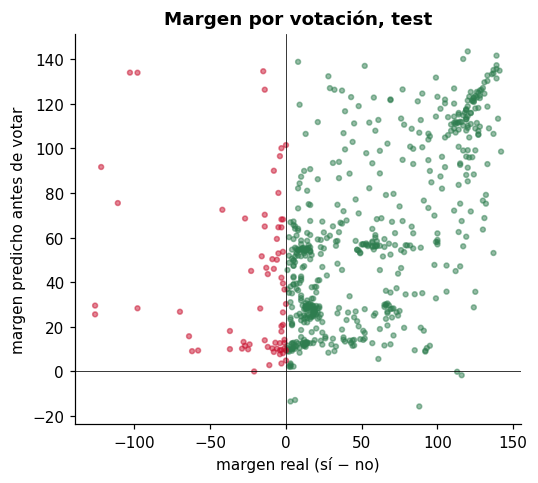

R-GCN, todas                             0.880
siempre gana el sí, todas                0.887
R-GCN, disputadas                        0.861
siempre gana el sí, disputadas           0.865
votaciones de test                     627.000
votaciones donde ganó el no             71.000
de esas, detectadas por R-GCN            0.014
error medio en votos a favor            15.625
correlación margen real vs predicho      0.574
dtype: float64

In [25]:
tA = test.assign(p_si=pA_media[:, 0], p_no=pA_media[:, 1])
agg = tA.groupby("votacion_id").agg(si=("p_si", "sum"), no=("p_no", "sum")).join(
    vot.set_index("votacion_id")[["gana_si", "disputada", "total_si", "total_no"]])
agg["pred"] = agg.si > agg.no
acierto = agg.pred == agg.gana_si
rech = ~agg.gana_si
res_votacion = {
    "R-GCN, todas": acierto.mean(),
    "siempre gana el sí, todas": agg.gana_si.mean(),
    "R-GCN, disputadas": acierto[agg.disputada].mean(),
    "siempre gana el sí, disputadas": agg.gana_si[agg.disputada].mean(),
    "votaciones de test": len(agg),
    "votaciones donde ganó el no": int(rech.sum()),
    "de esas, detectadas por R-GCN": (~agg.pred[rech]).mean(),
    "error medio en votos a favor": (agg.si - agg.total_si).abs().mean(),
    "correlación margen real vs predicho": np.corrcoef(agg.total_si - agg.total_no, agg.si - agg.no)[0, 1],
}
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(agg.total_si - agg.total_no, agg.si - agg.no, s=10, alpha=0.5, c=np.where(agg.gana_si, C_SI, C_NO))
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("margen real (sí − no)"); ax.set_ylabel("margen predicho antes de votar")
ax.set_title("Margen por votación, test")
plt.tight_layout(); plt.savefig(FIG / "fig_margen.png"); plt.show()
pd.Series(res_votacion).round(3)

## 9. ¿Qué aprendió el modelo de cada diputado?

Embeddings finales de los diputados (semilla 0), proyectados a 2D con PCA y coloreados por partido.

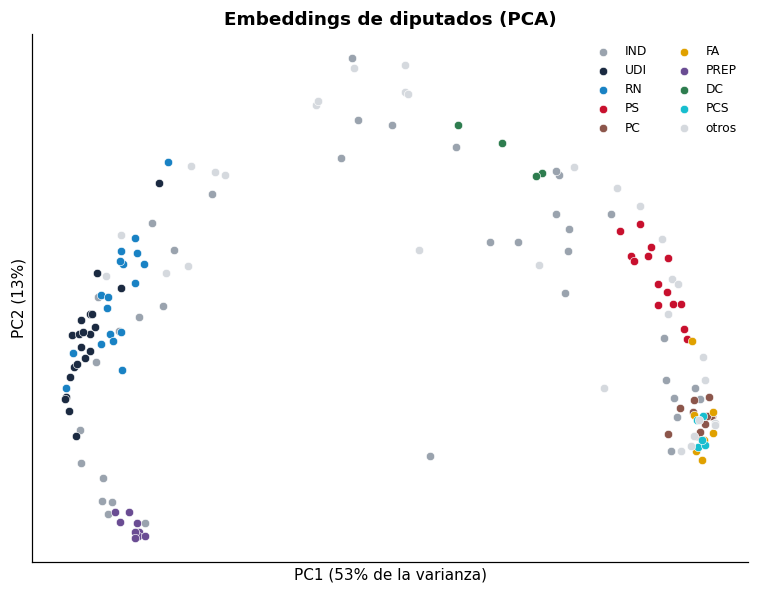

In [26]:
H = m0.codificar(aristas(V_SPLIT < 2, CFG["R-GCN completo"]))["diputado"].detach().cpu().numpy()
pca = PCA(2, random_state=0).fit(H)
Z = pca.transform(H)
fig, ax = plt.subplots(figsize=(7, 5.5))
for p in top_partidos + ["otros"]:
    m = part_dip.isin([p]).values if p != "otros" else ~part_dip.isin(top_partidos).values
    ax.scatter(Z[m, 0], Z[m, 1], s=30, color="#D5D9DE" if p == "otros" else color_partido[p], label=p,
               edgecolors="white", linewidths=0.4)
ax.legend(fontsize=8, ncol=2, frameon=False); ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Embeddings de diputados (PCA)")
plt.tight_layout(); plt.savefig(FIG / "fig_embeddings.png"); plt.show()

## 10. Guardar resultados

Todo lo que usan las presentaciones y los graphical abstracts queda en `../resultados/resultados.json`.

In [27]:
def a_dict(t):
    return {k: {c: round(float(v), 4) for c, v in fila.items()} for k, fila in t.to_dict(orient="index").items()}

salida = {
    "datos": {
        "votaciones_total_periodo": int(pd.read_csv(DATOS / "votaciones.csv").shape[0]),
        "votaciones_proyecto_ley": int(len(vot)), "votos": int(len(votos)), "proyectos": int(len(bol)),
        "diputados": int(len(dip_ids)), "partidos": int(len(partidos)), "comisiones": int(len(comisiones)),
        "autorias": int(len(aut)), "aristas_similar": int(len(src_sim)), "aristas_mismo_proyecto": int(len(src_mp)),
        "clases": votos.y.value_counts(normalize=True).sort_index().round(4).tolist(),
        "pct_independientes": float(votos.partido.isin(["IND", "SIN"]).mean()),
        "pct_disputadas": float(vot.disputada.mean()),
        "pct_mensajes": float((bol.patrocinador == "EJECUTIVO").mean()),
        "pct_rupturas": float(tasa_ruptura),
        "dias_test": int(vot.dia[vot.split == 2].nunique()),
        "split": {n: {"desde": str(vot.fecha[vot.split == s].min().date()), "hasta": str(vot.fecha[vot.split == s].max().date()),
                      "votaciones": int((vot.split == s).sum()), "votos": int((votos.split == s).sum())}
                  for s, n in enumerate(["train", "val", "test"])},
        "red_covotacion": {"nodos": G.number_of_nodes(), "aristas": G.number_of_edges(),
                           "homofilia": float(homofilia), "modularidad_partido": float(mod_partido),
                           "modularidad_louvain": float(mod_louvain), "comunidades_louvain": len(comunidades),
                           "acuerdo_intra": float(acuerdo_intra), "acuerdo_inter": float(acuerdo_inter)},
        "disciplina": tabla_disc.disciplina.round(3).to_dict(),
    },
    "hiperparametros": HP,
    "modelo_principal": HIB,
    "nombre_corto": {HIB: "R-GCN + NOMINATE", "R-GCN completo": "R-GCN"},
    "nominate": {"K": 2, "beta": float(nom_train.log_beta.exp()), "w2": float(nom_train.log_w.exp()[0]),
                 "sensibilidad_K": {int(k): {c: round(float(v), 4) for c, v in fila.items()}
                                    for k, fila in tabla_K.to_dict(orient="index").items()},
                 "b_por_semilla": [float(f["b"]) for f in corridas[HIB]]},
    "A": a_dict(tabla_A), "A_bloque": a_dict(tabla_Ab), "B": a_dict(tabla_B), "ablaciones": a_dict(tabla_abl),
    "pareado": pareado,
    "curva_visibles": {"frac": fracs, "rgcn": cg[:, 0].round(4).tolist(), "rgcn_sd": cg[:, 1].round(4).tolist(),
                       "partido": np.round(curva_par, 4).tolist(), "partido_covotacion": np.round(curva_mix, 4).tolist(),
                       "nominate": [None if np.isnan(v) else round(float(v), 4) for v in curva_nom],
                       "hibrido": np.round(curva_hib, 4).tolist()},
    "subgrupos": a_dict(tabla_sub),
    "rupturas": {"evaluados": int(eval_r.sum()), "n": int(y_rup.sum()), "tasa": float(y_rup.mean()),
                 "modelos": a_dict(tabla_rup)},
    "votacion": {k: round(float(v), 4) for k, v in res_votacion.items()},
    "semilla0_val": {"curva": [list(map(float, x)) for x in curva0]},
}
(RES / "resultados.json").write_text(json.dumps(salida, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: salida[k] for k in ["B", "rupturas", "A", "A_bloque", "pareado"]}, indent=1, ensure_ascii=False))

{
 "B": {
  "Mayoría del partido (visibles)": {
   "acc": 0.8722,
   "f1": 0.7074,
   "acc_sino": 0.899,
   "acc_sd": 0.0,
   "f1_sd": 0.0
  },
  "Mayoría de co-votación (visibles)": {
   "acc": 0.9206,
   "f1": 0.7594,
   "acc_sino": 0.9467,
   "acc_sd": 0.0,
   "f1_sd": 0.0
  },
  "Partido; independientes por co-votación": {
   "acc": 0.9134,
   "f1": 0.7557,
   "acc_sino": 0.9392,
   "acc_sd": 0.0,
   "f1_sd": 0.0
  },
  "NOMINATE (2 dimensiones)": {
   "acc": 0.9186,
   "f1": 0.6196,
   "acc_sino": 0.9604,
   "acc_sd": 0.0,
   "f1_sd": 0.0
  },
  "R-GCN completo": {
   "acc": 0.9169,
   "f1": 0.7549,
   "acc_sino": 0.9422,
   "acc_sd": 0.0026,
   "f1_sd": 0.0052
  },
  "R-GCN + NOMINATE": {
   "acc": 0.9237,
   "f1": 0.7589,
   "acc_sino": 0.9498,
   "acc_sd": 0.0011,
   "f1_sd": 0.0053
  }
 },
 "rupturas": {
  "evaluados": 27311,
  "n": 1428,
  "tasa": 0.05228662443704002,
  "modelos": {
   "Mayoría del partido (visibles)": {
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0.0,